# NYC Housing and Transportation - final notebook
**Members 1-4 consolidated submission.** Website/deployment (Member 5) is intentionally outside this notebook.

**Main question:** How do DOB housing/development application activity and recorded serious road crashes vary together across NYC ZIP codes during 2022-2025?

## Reading guide
1. Member 2: transportation source, EDA, cleaning, validation and aggregation.
2. Member 1: housing source, EDA, justified cleaning, job-aware aggregation and two questions.
3. Member 3: integration, post-join cleaning, validation and two questions.
4. Member 2: two completed cross-domain questions.
5. Member 4: two additional questions, key findings, limitations and NYC impact.

Execute top to bottom. Raw downloads are cached explicitly in ignored `data/raw/`; their JSON sidecars record source and retrieval time. The ZIP-level source exports and integrated CSV are regenerated. A fresh run needs internet, declared dependencies, and may take several minutes for the full housing window.

The team should review these AI-assisted corrections before submission; authorship credit is preserved, not evidence of individual approval.

## Part A - Member 2: transportation preparation
Prepare the crash reference before housing ZIP fallback.

# Data Engineering & Visualization – Milestone 1
## Member 2 – Transportation Dataset (SIRTA): Overview, EDA & Pre-Integration Cleaning

**Course:** Data Engineering and Visualization, Winter 2026 – GIU
**Team member:** Member 2 (Mariam) – Transportation dataset
**Output of this notebook:** `transport_clean_row_level.csv` (clean crash records) and `transport_clean.csv` (aggregated to **ZIP code × year**, ready for Member 3 to integrate with the housing dataset).

**Contents**
1. Dataset overview and reasoning for selection
2. Loading the data (with justification for any sampling)
3. Exploratory Data Analysis (EDA)
4. Pre-integration cleaning (missing values, duplicates, inconsistencies, formats, outliers)
5. Validation of cleaning (before vs. after)
6. Aggregation to the integration level (ZIP code × year) – the data contract
7. Research questions and visualizations (Member 2)
8. Prompts used, dataset links, and contribution statement

## 1. Dataset overview and reasoning for selection

| Item | Value |
|---|---|
| Dataset | **Serious Injury Response, Tracking & Analysis Program (SIRTA)** – catalog ID **T4** |
| Domain | Transportation |
| Publisher | NYC Department of Transportation (DOT) |
| Dataset ID | `xeqp-qz8h` |
| Link | https://data.cityofnewyork.us/Transportation/Serious-Injury-Response-Tracking-Analysis-Program-/xeqp-qz8h |
| Data dictionary | `SIRTA_Data_Dictionary.xlsx` (provided by the course) |
| Unit of analysis (row) | One serious vehicular crash that DOT analyzed and reported at a specific location |
| Rows / columns | 13,754 rows x 23 columns in the downloaded CSV (requirement: at least 9 columns) |
| Period covered | 01/01/2022 - 12/31/2024 (date format MM/DD/YYYY in the CSV export) |
| Temporal attributes | `Crash Date` (YYYY-MM-DD), `Crash Time` (HH:MM) |
| Geographic attributes | `Crash Borough`, `ZipCode`, `Latitude`/`Longitude`, `Community Board`, `Council District`, `NTA 2020`, `Census Tract 2020`, `BIN`, `BBL`, `Crash Police Precinct` |
| Update frequency | Quarterly publication (Local Law 49 of 2021) |

**Columns (from the data dictionary / portal):** Collision ID, Crash Date, Crash Time, Crash Police Precinct, Crash Borough, Total Non-Severe Injuries, Total Severe Injuries, Total Fatalities, Latitude, Longitude, On Street, Cross Street, Address, Highway Reference Marker, ZipCode, Similar Fatalities & Severe Injuries (3Y Lookback), Similar Fatalities & All Injuries (3Y Lookback), Community Board, Council District, BIN, BBL, Census Tract 2020, NTA 2020.

**Why this dataset?**
- It is **in the course catalog (T4)**, so no extra feasibility check is required.
- It has **ZIP code, borough and a crash date**, which are exactly the attributes needed to link it to housing data (permits / job filings) at **ZIP code × year** level.
- It carries **severity information** (severe injuries, fatalities), so we can ask richer questions than simple counts, e.g. whether street danger changes around areas of new residential development.

**Known issues (from the data dictionary, to be verified in the EDA):**
- Data comes directly from NYPD's FORMS system; **blank values mean the data was not recorded**, not zero.
- Only crashes classified as **severe ("A" injuries)** by the NYS DMV formula are included, so this is **not all crashes** – conclusions concern *serious* crashes only.
- Severity classification can lag by more than a year, so the most recent period may be incomplete.

**Granularity / aggregation plan.** The housing dataset has building-level records, while SIRTA has crash-level records. Neither will be joined record-to-record. Both are aggregated to **ZIP code × year** (a common geographic and temporal level that both datasets share). ZIP is fine-grained enough to see neighborhood patterns and coarse enough that each cell contains enough crashes/filings to be meaningful.

## 2. Loading and reproducibility
Use an explicit raw cache when present. Otherwise download the complete 2022-2025 window in stable pages; verify the row count before saving. No hidden fallback, arbitrary sample or partial 2026 year is used. Network failures remain visible. Delete the cache for an intentional refresh; its JSON sidecar records the source/time/count.

SIRTA covers serious-injury/fatal crashes, not all road collisions. The live API schema and crash severity may be revised.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "members").is_dir(), "Run from the repository root or notebooks directory."
CLEAN_DIR = ROOT / "data" / "clean"
RAW_DIR = ROOT / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "members" / "member1_housing"))
sys.path.insert(0, str(ROOT / "members" / "member3_integration"))
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.max_columns", 50)

import io
import json
import ssl
import re
import urllib.request
from urllib.parse import urlencode
import truststore
from sklearn.neighbors import NearestNeighbors
TRANSPORT_ID = "xeqp-qz8h"
API_URL = "https://data.cityofnewyork.us/resource/{}.csv"
LOCAL_CSV = RAW_DIR / "xeqp-qz8h.csv"
YEAR_MIN, YEAR_MAX = 2022, 2025
OUTPUT_ROW_LEVEL = CLEAN_DIR / "transport_clean_row_level.csv"
OUTPUT_AGGREGATED = CLEAN_DIR / "transport_clean.csv"

Inspect the outputs and validation checks for the preceding preparation step.

In [2]:
def load_sirta():
    if LOCAL_CSV.exists():
        print(f"Reading explicit raw cache: {LOCAL_CSV}")
        return pd.read_csv(LOCAL_CSV, low_memory=False)
    where = "crash_date >= '2022-01-01T00:00:00' AND crash_date < '2026-01-01T00:00:00'"
    def fetch(params):
        url = API_URL.format(TRANSPORT_ID) + "?" + urlencode(params)
        with urllib.request.urlopen(url, timeout=180, context=truststore.SSLContext(ssl.PROTOCOL_TLS_CLIENT)) as response:
            return pd.read_csv(io.BytesIO(response.read()), low_memory=False)
    expected = int(fetch({"$select": "count(*)", "$where": where}).iloc[0, 0])
    pages = []
    for offset in range(0, expected + 1, 50000):
        page = fetch({"$where": where, "$order": ":id", "$limit": 50000, "$offset": offset})
        pages.append(page)
        if len(page) < 50000:
            break
    frame = pd.concat(pages, ignore_index=True)
    assert len(frame) == expected, "Source changed while paging; retry before using the data."
    frame.to_csv(LOCAL_CSV, index=False)
    LOCAL_CSV.with_suffix(".json").write_text(json.dumps({
        "source": API_URL.format(TRANSPORT_ID), "where": where, "rows": len(frame),
        "downloaded_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    }, indent=2), encoding="utf-8")
    print(f"Downloaded {len(frame):,} rows, saved {LOCAL_CSV}")
    return frame

df_raw = load_sirta()
df = df_raw.copy()
display(df.head())

Reading explicit raw cache: C:\Users\voxic\AppData\Local\Temp\claude\C--MyFolders-Third-Year-Data-Engineering-and-Visualization-Project1-nyc-housing-transport\6b92afad-d7ee-4cee-b40b-237e692938d9\scratchpad\m3fix\data\raw\xeqp-qz8h.csv


,open_data_crash_id,crash_date,crash_time,crash_police_precinct,crash_borough,total_non_severe_injuries,total_severe_injuries,total_fatalities,latitude,longitude,on_street,cross_street,address,highway_reference_marker,zipcode,similar_fatalities_severe,similar_fatalities_all,community_board,council_district,bin,bbl,census_tract_2020_,neighborhood_tabulation_area_nta_2020_
0,4492364,2022-01-01T00:00:00.000,01:28,46,Bronx,1,1,0,40.858707,-73.90370,JEROME AVENUE,EAST 183 STREET,NaN,NaN,NaN,0.0,1,NaN,NaN,NaN,NaN,NaN,NaN
1,4491159,2022-01-01T00:00:00.000,04:33,46,Bronx,0,1,0,NaN,NaN,JEROME AVENUE,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,4491487,2022-01-01T00:00:00.000,05:55,47,Bronx,0,1,0,40.871550,-73.86428,NaN,NaN,3207 WALLACE AVENUE,NaN,NaN,0.0,0,212.0,12.0,2056281.0,2.045980e+09,372.0,BX1201
3,4491223,2022-01-01T00:00:00.000,10:42,43,Bronx,0,1,0,40.823673,-73.87233,BRONX RIVER PARKWAY,NaN,NaN,907HX1M11001,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,4491418,2022-01-01T00:00:00.000,20:55,49,Bronx,0,1,0,40.863945,-73.86452,BOSTON ROAD,WALLACE AVENUE,NaN,NaN,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN


Standardize the downloaded schema before selecting source columns.

In [3]:
def standardize_column_names(frame):
    """Lowercase snake_case names so the API and the portal CSV export look identical."""
    frame = frame.copy()
    frame.columns = (frame.columns.str.strip().str.lower()
                     .str.replace(r"[^0-9a-z]+", "_", regex=True).str.strip("_"))
    return frame

df = standardize_column_names(df)
print(df.columns.tolist())

['open_data_crash_id', 'crash_date', 'crash_time', 'crash_police_precinct', 'crash_borough', 'total_non_severe_injuries', 'total_severe_injuries', 'total_fatalities', 'latitude', 'longitude', 'on_street', 'cross_street', 'address', 'highway_reference_marker', 'zipcode', 'similar_fatalities_severe', 'similar_fatalities_all', 'community_board', 'council_district', 'bin', 'bbl', 'census_tract_2020', 'neighborhood_tabulation_area_nta_2020']


Resolve the source column names and parse source date formats explicitly.

In [4]:
def find_column(frame, *keywords):
    """Return the first column whose name contains ALL keywords (robust to API/CSV naming differences)."""
    for column in frame.columns:
        if all(keyword in column for keyword in keywords):
            return column
    raise KeyError(f"No column contains {keywords}. Available: {frame.columns.tolist()}")

def parse_crash_dates(series):
    """Parse dates from either the portal CSV (MM/DD/YYYY) or the API (ISO timestamp)."""
    parsed = pd.to_datetime(series, format="%m/%d/%Y", errors="coerce")
    leftover = parsed.isna() & series.notna()
    if leftover.any():
        parsed[leftover] = pd.to_datetime(series[leftover], errors="coerce")
    return parsed

# Map the logical names we use below to the real column names in the downloaded file.
COL = {
    "collision_id": next(c for c in df.columns if "collision" in c or c.endswith("crash_id")),   # portal CSV: collision_id | API: open_data_crash_id
    "crash_date":   find_column(df, "crash", "date"),
    "crash_time":   find_column(df, "crash", "time"),
    "precinct":     find_column(df, "precinct"),
    "borough":      find_column(df, "borough") if any("borough" in c and "block" not in c for c in df.columns) else None,
    "non_severe":   find_column(df, "non", "severe"),
    "fatalities":   find_column(df, "fatalit") if not any(c.startswith("total_fatalit") for c in df.columns) else "total_fatalities",
    "latitude":     find_column(df, "latitude"),
    "longitude":    find_column(df, "longitude"),
    "zip":          find_column(df, "zip"),
}
# 'total_severe_injuries' must not be confused with 'total_non_severe_injuries'
COL["severe"] = next(c for c in df.columns if "severe" in c and "non" not in c and c.startswith("total"))
COL["borough"] = next(c for c in df.columns if "borough" in c and "block" not in c)
COL["fatalities"] = next(c for c in df.columns if c.startswith("total_fatalit"))
print(COL)

{'collision_id': 'open_data_crash_id', 'crash_date': 'crash_date', 'crash_time': 'crash_time', 'precinct': 'crash_police_precinct', 'borough': 'crash_borough', 'non_severe': 'total_non_severe_injuries', 'fatalities': 'total_fatalities', 'latitude': 'latitude', 'longitude': 'longitude', 'zip': 'zipcode', 'severe': 'total_severe_injuries'}


## 3. Exploratory Data Analysis (EDA)

Goal: understand the structure of the data, find quality problems, and see the main patterns *before* cleaning, so every cleaning decision in Section 4 is justified by evidence.

### 3.1 Structure: shape, data types, memory

In [5]:
print("Rows, columns:", df.shape)
print("Required: at least 9 columns ->", "OK" if df.shape[1] >= 9 else "NOT OK")
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "n_unique": df.nunique(),
})
summary

Rows, columns: (11958, 23)
Required: at least 9 columns -> OK


,dtype,non_null,n_unique
open_data_crash_id,int64,11958,11958
crash_date,str,11958,1460
crash_time,str,11958,1659
crash_police_precinct,int64,11958,78
crash_borough,str,11922,5
total_non_severe_injuries,int64,11958,15
total_severe_injuries,int64,11958,8
total_fatalities,int64,11958,6
latitude,float64,9683,7746
longitude,float64,9683,7445


### 3.2 Missing values
The data dictionary warns that blanks mean *not recorded*. We quantify them per column to decide which columns are usable, which can be repaired, and which should be dropped.

,missing_pct,missing_count
highway_reference_marker,91.988627,11000
bbl,82.714501,9891
bin,82.714501,9891
address,81.033618,9690
neighborhood_tabulation_area_nta_2020,76.952668,9202
council_district,76.952668,9202
community_board,76.952668,9202
census_tract_2020,76.952668,9202
zipcode,40.868038,4887
cross_street,39.279144,4697


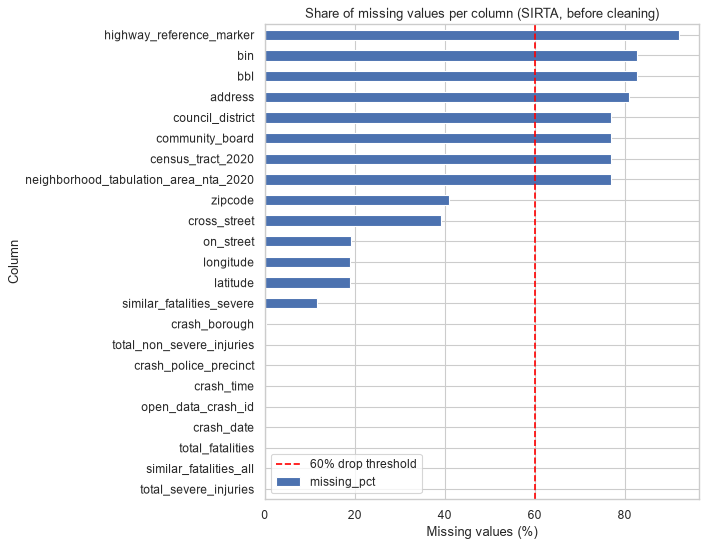

In [6]:
missing = (df.isna().mean() * 100).sort_values(ascending=False).rename("missing_pct").to_frame()
missing["missing_count"] = df.isna().sum()
display(missing)

fig, ax = plt.subplots(figsize=(9, 7))
missing["missing_pct"].sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.axvline(60, color="red", ls="--", label="60% drop threshold")
ax.set_title("Share of missing values per column (SIRTA, before cleaning)")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("Column")
ax.legend()
plt.tight_layout()
plt.show()

### 3.3 Descriptive statistics

In [7]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
display(df[numeric_cols].describe().T)
print("\nCategorical / text columns:")
display(df.select_dtypes(exclude="number").describe().T)

,count,mean,std,min,25%,50%,75%,max
open_data_crash_id,11958.0,4.691295e+06,1.067530e+05,4.491088e+06,4.599792e+06,4.695327e+06,4.782143e+06,4.870224e+06
crash_police_precinct,11958.0,6.777755e+01,3.461355e+01,1.000000e+00,4.200000e+01,6.800000e+01,1.040000e+02,1.230000e+02
total_non_severe_injuries,11958.0,2.713664e-01,8.237919e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.900000e+01
total_severe_injuries,11958.0,1.008363e+00,4.490578e-01,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,7.000000e+00
total_fatalities,11958.0,8.153537e-02,2.928582e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,5.000000e+00
latitude,9683.0,4.073118e+01,8.330138e-02,4.049967e+01,4.066810e+01,4.072798e+01,4.080153e+01,4.091247e+01
longitude,9683.0,-7.392096e+01,8.112754e-02,-7.424857e+01,-7.396770e+01,-7.392297e+01,-7.387535e+01,-7.370060e+01
zipcode,7071.0,1.082461e+04,5.424501e+02,1.000000e+04,1.045100e+04,1.120500e+04,1.123500e+04,1.169400e+04
similar_fatalities_severe,10565.0,9.522007e-02,4.209814e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,9.000000e+00
similar_fatalities_all,11958.0,1.545827e+00,6.014259e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2.960000e+02



Categorical / text columns:


,count,unique,top,freq
crash_date,11958,1460,2022-05-21T00:00:00.000,22
crash_time,11958,1659,00:00,163
crash_borough,11922,5,Brooklyn,3557
on_street,9676,2717,BROADWAY,155
cross_street,7261,3107,BROADWAY,74
address,2268,2220,101 EAST DRIVE,3
highway_reference_marker,958,760,907LX4M12071,5
neighborhood_tabulation_area_nta_2020,2756,221,MN0502,62


### 3.4 Duplicates

In [8]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated CollisionIDs:", df.duplicated(subset=[COL['collision_id']]).sum())

Fully duplicated rows: 0
Duplicated CollisionIDs: 0


### 3.5 Inconsistencies in key fields
We inspect the categorical/geographic fields we plan to use as integration keys (borough and ZIP) and the date/time fields.

In [9]:
print("Borough values (raw):")
print(df[COL["borough"]].value_counts(dropna=False))
print("\nZIP code - sample of raw values and dtype:", df[COL["zip"]].dtype)
print(df[COL["zip"]].dropna().astype(str).sample(10, random_state=1).tolist())
print("\nCrash date sample:", df[COL["crash_date"]].dropna().astype(str).head(3).tolist())
print("Crash time sample:", df[COL["crash_time"]].dropna().astype(str).head(3).tolist())

Borough values (raw):
crash_borough
Brooklyn         3557
Queens           2974
Manhattan        2448
Bronx            2365
Staten Island     578
NaN                36
Name: count, dtype: int64

ZIP code - sample of raw values and dtype: float64
['10000.0', '10025.0', '10475.0', '11355.0', '11412.0', '11212.0', '10001.0', '10003.0', '11368.0', '11238.0']

Crash date sample: ['2022-01-01T00:00:00.000', '2022-01-01T00:00:00.000', '2022-01-01T00:00:00.000']
Crash time sample: ['01:28', '04:33', '05:55']


### 3.6 Initial plots: what does the data look like?

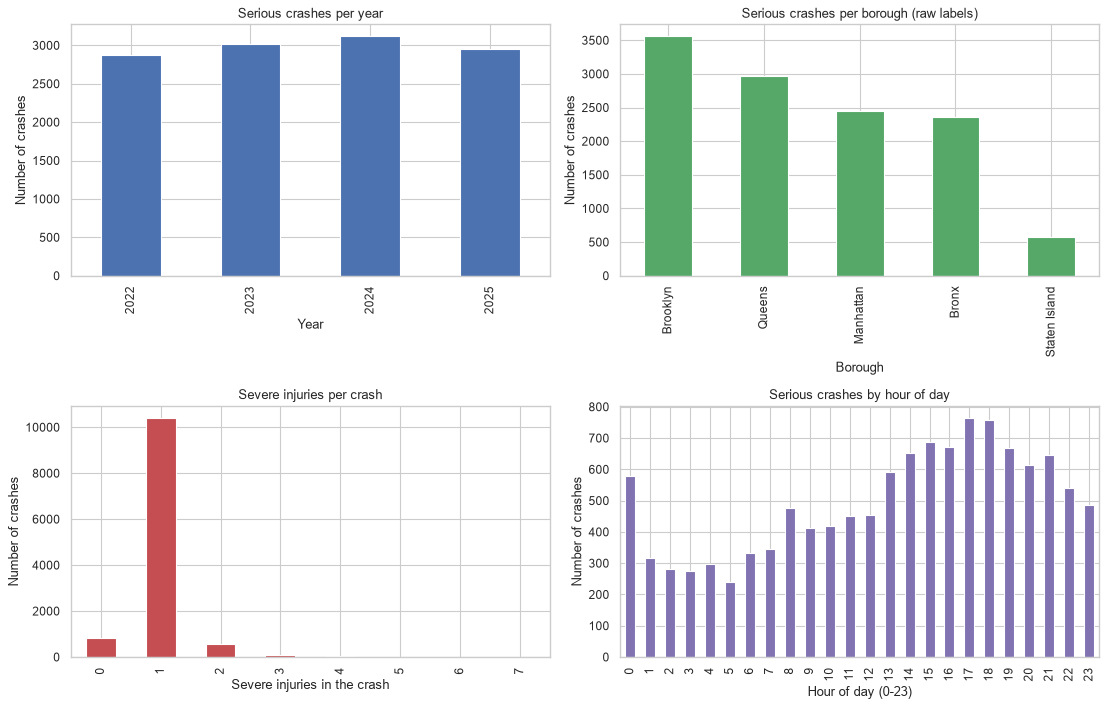

In [10]:
raw_dates = parse_crash_dates(df[COL["crash_date"]])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# (a) crashes per year
raw_dates.dt.year.value_counts().sort_index().plot.bar(ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title("Serious crashes per year")
axes[0, 0].set_xlabel("Year"); axes[0, 0].set_ylabel("Number of crashes")

# (b) crashes per borough
df[COL["borough"]].value_counts().plot.bar(ax=axes[0, 1], color="#55A868")
axes[0, 1].set_title("Serious crashes per borough (raw labels)")
axes[0, 1].set_xlabel("Borough"); axes[0, 1].set_ylabel("Number of crashes")

# (c) distribution of severe injuries per crash
df[COL["severe"]].value_counts().sort_index().head(15).plot.bar(ax=axes[1, 0], color="#C44E52")
axes[1, 0].set_title("Severe injuries per crash")
axes[1, 0].set_xlabel("Severe injuries in the crash"); axes[1, 0].set_ylabel("Number of crashes")

# (d) crashes per hour of day
hours = pd.to_datetime(df[COL["crash_time"]].astype(str), format="%H:%M", errors="coerce").dt.hour
hours.value_counts().sort_index().plot.bar(ax=axes[1, 1], color="#8172B2")
axes[1, 1].set_title("Serious crashes by hour of day")
axes[1, 1].set_xlabel("Hour of day (0-23)"); axes[1, 1].set_ylabel("Number of crashes")

plt.tight_layout()
plt.show()

Inspect the outputs and validation checks for the preceding preparation step.

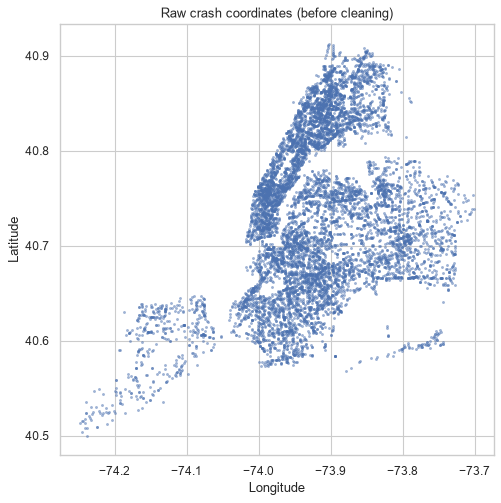

In [11]:
# Geographic sanity check on the raw coordinates (outliers appear as points far from NYC)
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(pd.to_numeric(df[COL["longitude"]], errors="coerce"),
           pd.to_numeric(df[COL["latitude"]], errors="coerce"), s=3, alpha=0.4)
ax.set_title("Raw crash coordinates (before cleaning)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.show()

**EDA take-aways (from the downloaded file: 13,754 rows x 23 columns):**
- **Empty rows:** 444 rows (3.2 %) are completely blank (no Collision ID, date or counts) - removed in 4.0.
- **Missing values:** `highway_reference_marker` (92 %), `address` (81 %), BIN/BBL (80 %), and `community_board`, `council_district`, census tract and NTA (72 %) are too sparse to use. **ZIP is missing in 41 %** and coordinates in 21 % of rows, so the integration key needs repair (4.4).
- **Formats:** dates are `MM/DD/YYYY` text; ZIP is read as float (`11205.0`); borough labels are title-case and ~4 % are missing.
- **Invalid values:** 44 ZIP values equal `10000`, which is a placeholder, not a real NYC ZIP.
- **Time coverage:** 2022-01-01 to 2026-06-30; **2026 is incomplete** (six months).
- **Severity:** most crashes (~84 %) have exactly one severe injury; about 7 % involve a fatality.

## 4. Pre-integration cleaning

Each step states **what** we do, **why**, and **which alternative** we considered.

### 4.0 Remove completely empty rows
The EDA shows about 3% of the rows have **no Collision ID, no date and no severity counts** (every key field is blank). They carry no information, are not crashes, and would all be treated as one "duplicate" in the next step, so we remove them first.

In [12]:
empty_rows = df.isna().all(axis=1)
print(f"Completely empty rows removed: {empty_rows.sum():,}")
df = df.loc[~empty_rows].copy()
missing_id = df[COL["collision_id"]].isna()
print(f"Rows without crash identifier removed: {missing_id.sum():,}")
df = df.loc[~missing_id].copy()

Completely empty rows removed: 0
Rows without crash identifier removed: 0


### 4.1 Remove duplicates
**Decision:** drop exact duplicate rows, then keep one row per `CollisionID`.
**Why:** one row = one crash, so a repeated `CollisionID` double-counts the crash and would inflate the aggregated crash counts that we later correlate with housing.
**Alternative:** keep the most severe duplicate. Because duplicates should be identical copies, keeping the first is equivalent and simpler.

In [13]:
def remove_duplicates(frame, id_col):
    before = len(frame)
    frame = frame.drop_duplicates()
    frame = frame.drop_duplicates(subset=[id_col], keep="first")
    print(f"Removed {before - len(frame):,} duplicate rows ({before:,} -> {len(frame):,}).")
    return frame

df = remove_duplicates(df, COL["collision_id"])

Removed 0 duplicate rows (11,958 -> 11,958).


### 4.2 Standardize formats (dates, strings, categories, geographic identifiers)
- **Dates:** parse `crash_date` to `datetime`; derive `year`, `month`, `day_of_week`. Invalid or impossible dates (unparseable or in the future) are dropped because the year is part of our integration key.
- **Time:** parse `crash_time` (HH:MM) to hour and a `time_of_day` category (night / morning / afternoon / evening).
- **Borough:** strip whitespace and convert to UPPERCASE (`BROOKLYN`, `BRONX`, `MANHATTAN`, `QUEENS`, `STATEN ISLAND`) to match the agreed data contract.
- **ZIP code:** store as a **5-digit string** (never a number, otherwise leading zeros/`.0` break the join).
- **Counts:** injuries/fatalities converted to integers; negative values are invalid.
- **Column names:** lowercase snake_case (done in Section 2).

In [14]:
VALID_BOROUGHS = {"BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"}

def standardize_formats(frame, col):
    frame = frame.copy()

    # --- dates and time
    frame["crash_date"] = parse_crash_dates(frame[col["crash_date"]])
    frame["year"] = frame["crash_date"].dt.year
    frame["month"] = frame["crash_date"].dt.month
    frame["day_of_week"] = frame["crash_date"].dt.day_name()
    parsed_time = pd.to_datetime(frame[col["crash_time"]].astype(str).str.strip(), format="%H:%M", errors="coerce")
    frame["crash_hour"] = parsed_time.dt.hour
    frame["time_of_day"] = pd.cut(frame["crash_hour"], bins=[-1, 5, 11, 17, 21, 24],
                                  labels=["night", "morning", "afternoon", "evening", "night_late"])
    frame["time_of_day"] = frame["time_of_day"].astype(str).replace({"night_late": "night", "nan": np.nan})

    # --- borough: trim + uppercase
    frame["borough"] = frame[col["borough"]].astype("string").str.strip().str.upper()

    # --- ZIP: 5-digit string; remove '.0' left by float parsing; non 5-digit values -> NaN
    zip_text = (frame[col["zip"]].astype("string").str.strip()
                .str.replace(r"\.0$", "", regex=True).str.extract(r"^(\d{5})(?:-\d{4})?$", expand=False))
    frame["zip_code"] = zip_text

    # --- numeric columns
    for name in ("severe", "non_severe", "fatalities"):
        frame[f"{name}_count"] = pd.to_numeric(frame[col[name]], errors="coerce")
    frame["latitude"] = pd.to_numeric(frame[col["latitude"]], errors="coerce")
    frame["longitude"] = pd.to_numeric(frame[col["longitude"]], errors="coerce")
    return frame

df = standardize_formats(df, COL)
df[["crash_date", "year", "crash_hour", "time_of_day", "borough", "zip_code",
    "severe_count", "non_severe_count", "fatalities_count"]].head()

,crash_date,year,crash_hour,time_of_day,borough,zip_code,severe_count,non_severe_count,fatalities_count
0,2022-01-01,2022,1,night,BRONX,<NA>,1,1,0
1,2022-01-01,2022,4,night,BRONX,<NA>,1,0,0
2,2022-01-01,2022,5,night,BRONX,<NA>,1,0,0
3,2022-01-01,2022,10,morning,BRONX,<NA>,1,0,0
4,2022-01-01,2022,20,evening,BRONX,<NA>,1,0,0


### 4.3 Check inconsistent data (domain rules)
Rules applied:
1. `crash_date` must be a valid date and **not in the future**.
2. Borough must be one of the 5 NYC boroughs.
3. Injury and fatality counts must be **non-negative**.
4. Coordinates must lie inside a bounding box around New York City (lat 40.45–40.95, lon −74.30 – −73.65); anything else is a data-entry error.
5. ZIP codes must be inside NYC ZIP ranges (100xx–104xx, 110xx–116xx) – this catches typos such as `00000` or ZIPs outside the city.
6. **Borough–ZIP consistency:** a ZIP should map to one borough; where it maps to several we keep the dominant borough (the mode) for the ZIP.

**Decision:** invalid values are set to missing (not silently kept) and then handled by the missing-value strategy in 4.4. Rows without a usable date are dropped (the year is required).

In [15]:
def apply_domain_rules(frame):
    frame = frame.copy()
    report = {}

    # Rule 1: dates
    bad_date = frame["crash_date"].isna() | (frame["crash_date"] > pd.Timestamp.today())
    report["invalid/future date"] = int(bad_date.sum())
    frame = frame.loc[~bad_date].copy()

    # Rule 2: boroughs
    bad_borough = ~frame["borough"].isin(VALID_BOROUGHS) & frame["borough"].notna()
    report["invalid borough label -> NaN"] = int(bad_borough.sum())
    frame.loc[bad_borough, "borough"] = np.nan

    # Rule 3: negative counts
    for name in ("severe_count", "non_severe_count", "fatalities_count"):
        negative = frame[name] < 0
        report[f"negative {name} -> NaN"] = int(negative.sum())
        frame.loc[negative, name] = np.nan

    # Rule 4: coordinates inside the NYC bounding box
    outside = ~(frame["latitude"].between(40.45, 40.95) & frame["longitude"].between(-74.30, -73.65))
    outside &= frame["latitude"].notna() | frame["longitude"].notna()
    report["coordinates outside NYC -> NaN"] = int(outside.sum())
    frame.loc[outside, ["latitude", "longitude"]] = np.nan

    # Rule 5: NYC ZIP ranges
    zip_number = pd.to_numeric(frame["zip_code"], errors="coerce")
    valid_zip = zip_number.between(10001, 10499) | zip_number.between(11001, 11699)
    bad_zip = frame["zip_code"].notna() & ~valid_zip
    report["ZIP outside NYC ranges -> NaN"] = int(bad_zip.sum())
    frame.loc[bad_zip, "zip_code"] = np.nan

    print(pd.Series(report).to_string())
    return frame

df = apply_domain_rules(df)

invalid/future date                  0
invalid borough label -> NaN         0
negative severe_count -> NaN         0
negative non_severe_count -> NaN     0
negative fatalities_count -> NaN     0
coordinates outside NYC -> NaN       0
ZIP outside NYC ranges -> NaN       36


Inspect ZIP/borough label conflicts and use the observed dominant borough consistently.

In [16]:
# Rule 6: borough-ZIP consistency. Use the dominant borough of each ZIP.
zip_to_borough = (df.dropna(subset=["zip_code", "borough"])
                    .groupby("zip_code")["borough"].agg(lambda s: s.mode().iloc[0]))
ambiguous = (df.dropna(subset=["zip_code", "borough"]).groupby("zip_code")["borough"].nunique() > 1).sum()
print(f"ZIP codes appearing in more than one borough label: {ambiguous}")

df["borough"] = df["zip_code"].map(zip_to_borough).fillna(df["borough"])

ZIP codes appearing in more than one borough label: 2


### 4.4 Handle missing values (justify drop vs. impute)

**Column level**
- Columns with **> 60 % missing** and no role in the analysis (e.g. highway reference marker, BIN, BBL, address) are **dropped**. Imputing them would invent information, and they are not needed for ZIP × year aggregation.
- Columns that are always needed (`crash_date`, severity counts) are never imputed; rows missing them are dropped.

**Row level – ZIP code (our integration key)**
- The dictionary says a missing ZIP means *not recorded*. If the crash still has valid coordinates, the ZIP is **recovered from the nearest crash that has a ZIP** (1-nearest-neighbour on latitude/longitude) – but only if that neighbour is very close (≈ 500 m) so we do not assign a wrong ZIP.
- Rows with **no ZIP and no usable coordinates** are **dropped**: without the key they cannot take part in the ZIP × year integration. The number dropped is reported.

**Alternatives considered:** (a) impute ZIP with the most frequent ZIP of the borough – rejected because it would bias counts toward one ZIP; (b) keep rows with missing ZIP and group them as "UNKNOWN" – rejected because they could never be joined to housing data.

**Count columns:** a blank means *not recorded*, not zero, so we never fill missing counts with 0. Rows with a missing severe-injury count are dropped; gaps in the secondary counts (non-severe, fatalities) stay as missing and are skipped by the aggregation.

In [17]:
MISSING_DROP_THRESHOLD = 0.60

def drop_sparse_columns(frame, threshold=MISSING_DROP_THRESHOLD, protect=()):
    share = frame.isna().mean()
    to_drop = [c for c in share[share > threshold].index if c not in protect]
    print("Dropping columns with >60% missing:", to_drop)
    return frame.drop(columns=to_drop)

PROTECTED = ["crash_date", "year", "month", "borough", "zip_code", "latitude", "longitude",
             "severe_count", "non_severe_count", "fatalities_count", "crash_hour", "time_of_day", "day_of_week"]
df = drop_sparse_columns(df, protect=PROTECTED)

Dropping columns with >60% missing: ['address', 'highway_reference_marker', 'community_board', 'council_district', 'bin', 'bbl', 'census_tract_2020', 'neighborhood_tabulation_area_nta_2020']


Recover only nearby missing ZIPs, report remaining missingness and drop unusable integration keys.

In [18]:
def impute_zip_from_nearest_crash(frame, max_distance_deg=0.005):
    """Fill a missing ZIP with the ZIP of the nearest crash (same file) that has one.
    0.005 degrees is roughly 500 m in NYC; farther neighbours are not trusted."""
    frame = frame.copy()
    known = frame.dropna(subset=["zip_code", "latitude", "longitude"])
    target = frame[frame["zip_code"].isna() & frame["latitude"].notna() & frame["longitude"].notna()]
    print(f"Missing ZIP: {frame['zip_code'].isna().sum():,} | recoverable via coordinates: {len(target):,}")
    if len(target) == 0 or len(known) == 0:
        return frame, 0
    nn = NearestNeighbors(n_neighbors=1).fit(known[["latitude", "longitude"]])
    distance, index = nn.kneighbors(target[["latitude", "longitude"]])
    close_enough = distance[:, 0] <= max_distance_deg
    filled_index = target.index[close_enough]
    frame.loc[filled_index, "zip_code"] = known["zip_code"].to_numpy()[index[close_enough, 0]]
    # borough follows the (new) ZIP
    frame.loc[filled_index, "borough"] = frame.loc[filled_index, "zip_code"].map(zip_to_borough).fillna(frame.loc[filled_index, "borough"])
    print(f"ZIP imputed for {len(filled_index):,} rows.")
    return frame, len(filled_index)

df, n_zip_imputed = impute_zip_from_nearest_crash(df)

# Drop rows that still lack the integration key or the core measures
before = len(df)
df = df.dropna(subset=["zip_code", "severe_count"]).copy()
print(f"Dropped {before - len(df):,} rows without ZIP or severe-injury count ({before:,} -> {len(df):,}).")

# Remaining numeric gaps in the secondary counts: blank = 'not recorded', so keep them as NaN (not 0)
# and let the aggregation skip them; they are reported rather than invented.
print(df[["non_severe_count", "fatalities_count", "borough", "crash_hour"]].isna().sum())
df = df.dropna(subset=["borough"]).copy()

Missing ZIP: 4,923 | recoverable via coordinates: 3,814


ZIP imputed for 3,496 rows.
Dropped 1,427 rows without ZIP or severe-injury count (11,958 -> 10,531).
non_severe_count    0
fatalities_count    0
borough             0
crash_hour          0
dtype: int64


### 4.5 Restrict to the common time window
To make the two datasets comparable we keep only years shared with the housing dataset. The SIRTA file runs from 2022-01-01 to **2026-06-30**: 2022-2025 are complete years, while **2026 covers only six months**, so comparing its yearly totals with full years would look like a (false) drop in crashes. By default we therefore keep **2022-2025**; change `YEAR_MIN`/`YEAR_MAX` in Section 2 if the team agrees on another window. DOT's severity classification can also lag, which is documented as a limitation.

In [19]:
if YEAR_MIN is not None:
    df = df[df["year"] >= YEAR_MIN]
if YEAR_MAX is not None:
    df = df[df["year"] <= YEAR_MAX]
df["year"] = df["year"].astype(int)
print("Years kept:", sorted(df["year"].unique()), "| rows:", len(df))

Years kept: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)] | rows: 10531


### 4.6 Outlier detection and treatment
Two complementary methods:
1. **Domain rules** (already applied in 4.3): impossible coordinates, dates, negative counts.
2. **IQR rule** on the severity counts per crash: values above `Q3 + 1.5·IQR` are *flagged*.

**Decision:** statistical outliers in severity counts are **flagged but kept**. A crash with many severe injuries is rare but **real** (e.g. a multi-victim crash) and is exactly what a safety analysis should capture; deleting it would hide the most important events. The `is_outlier_severe` flag lets the website and analysis exclude them if needed. For the ZIP × year aggregates (Section 6) we repeat the IQR check and flag unusually high-crash ZIPs.
**Alternative considered:** winsorizing/capping – rejected because it would artificially reduce real severity.

**Note on the IQR result:** about 84 % of crashes have exactly **1** severe injury, so Q1 = Q3 = 1 and the IQR is 0: the bounds collapse to [1, 1] and *any* crash with 2+ severe injuries is flagged (~6 %). This is expected for a heavily concentrated count variable and the flag is only informative ("multi-victim crash"), which is another reason we keep and flag instead of delete. The more meaningful IQR check is the one on ZIP × year crash counts in Section 6.

IQR bounds for severe injuries per crash: [1.0, 1.0] -> 614 flagged crashes (5.83%).


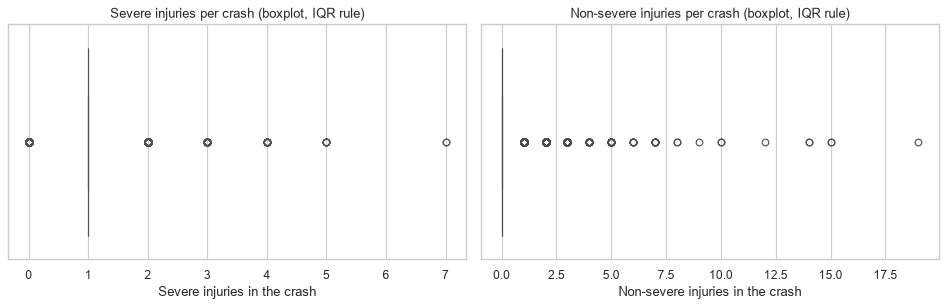

In [20]:
def iqr_bounds(series, factor=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    spread = q3 - q1
    return q1 - factor * spread, q3 + factor * spread

lower, upper = iqr_bounds(df["severe_count"])
df["is_outlier_severe"] = df["severe_count"] > upper
print(f"IQR bounds for severe injuries per crash: [{lower:.1f}, {upper:.1f}] -> "
      f"{df['is_outlier_severe'].sum():,} flagged crashes ({df['is_outlier_severe'].mean():.2%}).")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["severe_count"], ax=axes[0], color="#C44E52")
axes[0].set_title("Severe injuries per crash (boxplot, IQR rule)")
axes[0].set_xlabel("Severe injuries in the crash")
sns.boxplot(x=df["non_severe_count"].dropna(), ax=axes[1], color="#4C72B0")
axes[1].set_title("Non-severe injuries per crash (boxplot, IQR rule)")
axes[1].set_xlabel("Non-severe injuries in the crash")
plt.tight_layout()
plt.show()

## 5. Validation of the cleaning (before vs. after)
These checks and plots demonstrate that the cleaning did what we intended.

In [21]:
checks = pd.DataFrame({
    "rows": [len(df_raw), len(df)],
    "missing_zip": [df_raw[[c for c in df_raw.columns if 'zip' in c.lower()][0]].isna().sum(), df["zip_code"].isna().sum()],
    "duplicated_collision_ids": [df_raw.duplicated(subset=[COL['collision_id']]).sum(), df.duplicated(subset=[COL['collision_id']]).sum()],
}, index=["raw", "clean"])
display(checks)

assert df["zip_code"].str.fullmatch(r"\d{5}").all(), "ZIP must be a 5-digit string"
assert df["borough"].isin(VALID_BOROUGHS).all(), "borough labels must be standardized"
assert (df[["severe_count"]] >= 0).all().all(), "negative counts found"
assert df["latitude"].dropna().between(40.45, 40.95).all()
print("All validation assertions passed.")

,rows,missing_zip,duplicated_collision_ids
raw,11958,4887,0
clean,10531,0,0


All validation assertions passed.


Visualize the distributions or validation results for the preceding analysis step.

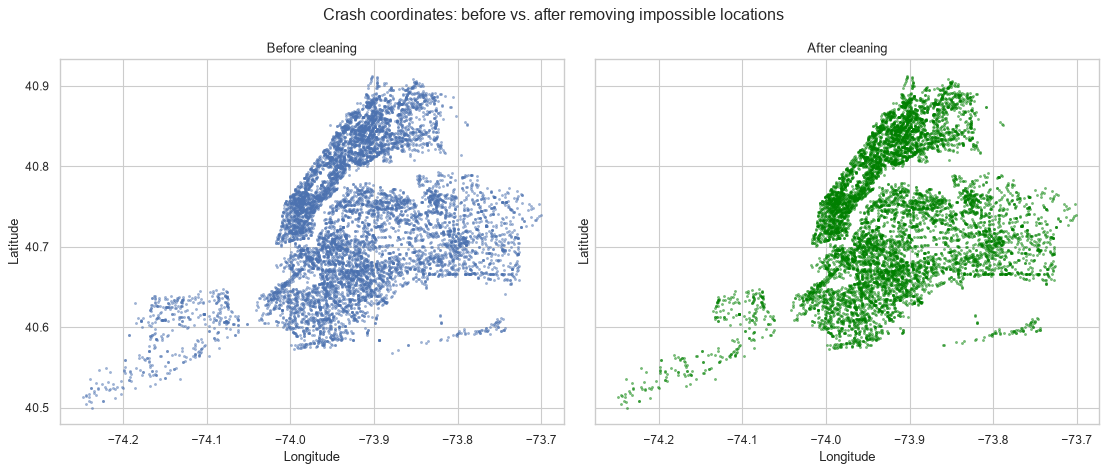

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
axes[0].scatter(pd.to_numeric(df_raw[[c for c in df_raw.columns if 'longitude' in c.lower()][0]], errors="coerce"),
                pd.to_numeric(df_raw[[c for c in df_raw.columns if 'latitude' in c.lower()][0]], errors="coerce"), s=3, alpha=0.4)
axes[0].set_title("Before cleaning")
axes[1].scatter(df["longitude"], df["latitude"], s=3, alpha=0.4, color="green")
axes[1].set_title("After cleaning")
for ax in axes:
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
fig.suptitle("Crash coordinates: before vs. after removing impossible locations")
plt.tight_layout()
plt.show()

Summarize retained crash counts by standardized borough.

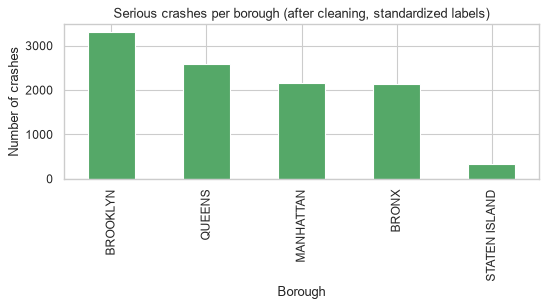

In [23]:
borough_after = df["borough"].value_counts()
fig, ax = plt.subplots(figsize=(7, 4))
borough_after.plot.bar(ax=ax, color="#55A868")
ax.set_title("Serious crashes per borough (after cleaning, standardized labels)")
ax.set_xlabel("Borough"); ax.set_ylabel("Number of crashes")
plt.tight_layout(); plt.show()

## 6. ZIP code x year aggregation
Count crashes and sum recorded injuries/deaths. Secondary counts remain unknown if an entire group is missing; missing is not zero. Nighttime means hours 00-05 and 22-23. **Unknown time is excluded from the share's denominator**, not counted as daytime. Export nighttime numerators/known-time denominators so later aggregation can weight shares correctly.

ZIP recovery is approximate and reported above; broad numeric ZIP screening is not a USPS boundary validation. These are counts in the retained ZIP-known subset, not a census of every NYC crash.

In [24]:
def aggregate_to_zip_year(frame):
    frame = frame.copy()
    frame["is_fatal_crash"] = frame["fatalities_count"].gt(0).astype(float).where(frame["fatalities_count"].notna())
    frame["is_night"] = frame["time_of_day"].eq("night").astype(float).where(frame["crash_hour"].notna())
    aggregated = frame.groupby(["zip_code", "year"]).agg(
        borough=("borough", lambda s: s.mode().iloc[0]),
        crash_count=("severe_count", "size"),
        severe_injuries_total=("severe_count", lambda s: s.sum(min_count=1)),
        non_severe_injuries_total=("non_severe_count", lambda s: s.sum(min_count=1)),
        fatalities_total=("fatalities_count", lambda s: s.sum(min_count=1)),
        fatal_crash_count=("is_fatal_crash", lambda s: s.sum(min_count=1)),
        severe_per_crash=("severe_count", "mean"),
        night_crash_share=("is_night", "mean"),
        night_crash_count=("is_night", "sum"),
        crashes_with_known_time=("is_night", "count"),
        avg_latitude=("latitude", "mean"),
        avg_longitude=("longitude", "mean"),
    ).reset_index()
    low, high = iqr_bounds(aggregated["crash_count"])
    aggregated["is_outlier_zip_year"] = aggregated["crash_count"] > high
    aggregated["zip_code"] = aggregated["zip_code"].astype(str)
    return aggregated

df_transport_agg = aggregate_to_zip_year(df)
print(df_transport_agg.shape)
display(df_transport_agg.head())

(702, 15)


,zip_code,year,borough,crash_count,severe_injuries_total,non_severe_injuries_total,fatalities_total,fatal_crash_count,severe_per_crash,night_crash_share,night_crash_count,crashes_with_known_time,avg_latitude,avg_longitude,is_outlier_zip_year
0,10001,2022,MANHATTAN,17,18.0,4.0,1.0,1.0,1.058824,0.176471,3.0,17,40.750403,-73.995298,False
1,10001,2023,MANHATTAN,26,24.0,9.0,2.0,2.0,0.923077,0.307692,8.0,26,40.751362,-73.996973,False
2,10001,2024,MANHATTAN,21,24.0,18.0,0.0,0.0,1.142857,0.333333,7.0,21,40.750665,-73.994919,False
3,10001,2025,MANHATTAN,18,17.0,3.0,1.0,1.0,0.944444,0.222222,4.0,18,40.750087,-73.995602,False
4,10002,2022,MANHATTAN,23,28.0,4.0,2.0,2.0,1.217391,0.652174,15.0,23,40.716705,-73.984744,False


Inspect the outputs and validation checks for the preceding preparation step.

In [25]:
# Final quality checks on the aggregated table
assert not df_transport_agg.duplicated(subset=["zip_code", "year"]).any(), "key must be unique"
assert pd.api.types.is_string_dtype(df_transport_agg["zip_code"]), "ZIP must be text"
print(df_transport_agg.isna().sum()[lambda s: s > 0])
display(df_transport_agg.describe().T)

avg_latitude     3
avg_longitude    3
dtype: int64


,count,mean,std,min,25%,50%,75%,max
year,702.0,2023.514245,1.116187,2022.000000,2023.000000,2024.000000,2025.000000,2025.000000
crash_count,702.0,15.001425,10.144955,1.000000,7.000000,13.000000,22.000000,48.000000
severe_injuries_total,702.0,15.341880,10.618797,0.000000,7.000000,13.000000,22.000000,51.000000
non_severe_injuries_total,702.0,3.898860,4.328161,0.000000,1.000000,3.000000,6.000000,35.000000
fatalities_total,702.0,0.915954,1.156783,0.000000,0.000000,1.000000,1.000000,8.000000
fatal_crash_count,702.0,0.877493,1.098218,0.000000,0.000000,1.000000,1.000000,8.000000
severe_per_crash,702.0,1.015664,0.152715,0.000000,0.961538,1.000000,1.062500,2.000000
night_crash_share,702.0,0.242675,0.182533,0.000000,0.130435,0.230769,0.333333,1.000000
night_crash_count,702.0,3.690883,3.185631,0.000000,1.000000,3.000000,5.000000,17.000000
crashes_with_known_time,702.0,15.001425,10.144955,1.000000,7.000000,13.000000,22.000000,48.000000


Export the validated row-level and ZIP-year tables to the shared clean-data directory.

In [26]:
EXPORT_COLUMNS = [COL["collision_id"], "crash_date", "year", "month", "day_of_week", "crash_hour", "time_of_day",
                  "borough", "zip_code", "latitude", "longitude", "severe_count", "non_severe_count",
                  "fatalities_count", "is_outlier_severe", "on_street", "cross_street", COL["precinct"]]
df_clean_export = df[[c for c in EXPORT_COLUMNS if c in df.columns]].copy()
df_clean_export = df_clean_export.rename(columns={COL["collision_id"]: "collision_id", COL["precinct"]: "precinct"})
df_clean_export.to_csv(OUTPUT_ROW_LEVEL, index=False)
df_transport_agg.to_csv(OUTPUT_AGGREGATED, index=False)
print(f"Saved {OUTPUT_ROW_LEVEL} ({len(df_clean_export):,} rows) and {OUTPUT_AGGREGATED} ({len(df_transport_agg):,} rows).")

Saved C:\Users\voxic\AppData\Local\Temp\claude\C--MyFolders-Third-Year-Data-Engineering-and-Visualization-Project1-nyc-housing-transport\6b92afad-d7ee-4cee-b40b-237e692938d9\scratchpad\m3fix\data\clean\transport_clean_row_level.csv (10,531 rows) and C:\Users\voxic\AppData\Local\Temp\claude\C--MyFolders-Third-Year-Data-Engineering-and-Visualization-Project1-nyc-housing-transport\6b92afad-d7ee-4cee-b40b-237e692938d9\scratchpad\m3fix\data\clean\transport_clean.csv (702 rows).


## Part B - Member 1: corrected housing preparation and research
Official building postcode is preferred; amendment unit duplication is removed.

# Member 1 - Housing dataset and EDA
**Original contributor:** Mostafa. **Dataset H5:** [DOB NOW Build Job Application Filings](https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd).

We study application activity, not completed homes. The full 2022-2025 filing window is used, not a row-limited sample. This revised notebook fixes the earlier unit double-counting and uses the building `postcode` field now verified in the live API. `zip` remains the owner's mailing ZIP and is never a building-location key.

Run Member 2's cleaning section first (its row-level CSV is also committed). Member 3 alone writes the final integrated CSV. Helpers contain the tested cleaning logic; all decisions and results are visible here.

## 1. Environment and reproducible paths
Resolve files from the repository, without creating duplicate data folders inside notebooks.

In [27]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "members").is_dir(), "Run from the repository root or notebooks directory."
CLEAN_DIR = ROOT / "data" / "clean"
RAW_DIR = ROOT / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "members" / "member1_housing"))
sys.path.insert(0, str(ROOT / "members" / "member3_integration"))
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.max_columns", 50)

## 2. Source, columns and complete-window download
The API has geography (`borough`, `postcode`, latitude/longitude), time (`filing_date`), identity (`job_filing_number`), building measures, cost and `job_type`. It also contains many personal/administrative fields that are not needed.

The downloader explicitly selects analysis columns, filters 2022-2025, pages in stable ID order, and checks its row count against the server count. A cached raw CSV is used explicitly, never as a hidden fallback after a failed download. Delete it to request a refresh; a companion JSON records provenance. Missing required fields fail with a clear error.

In [28]:
from fetch_h5_data import main as download_housing
housing_raw_path = RAW_DIR / "w9ak-ipjd.csv"
if not housing_raw_path.exists():
    download_housing()
print(f"Reading explicit raw cache: {housing_raw_path}")
df_raw = pd.read_csv(housing_raw_path, low_memory=False)
print(f"Raw shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
display(df_raw.head())
display(df_raw.dtypes.to_frame("dtype"))

Reading explicit raw cache: C:\Users\voxic\AppData\Local\Temp\claude\C--MyFolders-Third-Year-Data-Engineering-and-Visualization-Project1-nyc-housing-transport\6b92afad-d7ee-4cee-b40b-237e692938d9\scratchpad\m3fix\data\raw\w9ak-ipjd.csv


Raw shape: 598,706 rows x 38 columns


,job_filing_number,filing_date,filing_status,borough,block,lot,bin,commmunity_board,house_no,street_name,zip,building_type,initial_cost,total_construction_floor_area,existing_stories,existing_height,existing_dwelling_units,proposed_no_of_stories,proposed_height,proposed_dwelling_units,latitude,longitude,council_district,census_tract,nta,first_permit_date,approved_date,current_status_date,work_on_floor,apt_condo_no_s,special_inspection_agency_number,signoff_date,built_1_information_value,built_2_information_value,built_2_a_information_value,built_2_b_information_value,postcode,job_type
0,B00244768-P3,2022-05-18T00:00:00.000,Approved,Brooklyn,1987,21,3057064,303.0,22,MONROE STREET,11101,2 Family,12500.0,1734.0,NaN,NaN,2.0,NaN,NaN,2.0,40.684585,-73.958175,36.0,229.0,Bedford-Stuyvesant (West),NaN,2022-06-02T13:28:51.000,2022-06-02T17:28:54.000,"Cellar, Floor Number(s) 2 through 3, Floor Num...","Apr A, Apt B",001310,NaN,NaN,NaN,NaN,NaN,11238.0,Alteration
1,B00464221-S2,2023-11-11T00:00:00.000,Permit Entire,Brooklyn,1566,4,3042533,316.0,29,MARCONI PLACE,11435,2 Family,0.0,1456.0,2.0,24.0,2.0,2.0,24.0,2.0,40.676822,-73.912718,41.0,301.0,Ocean Hill,2025-09-12T00:00:00.000,2023-11-13T15:26:00.000,2025-09-12T19:20:57.000,"Cellar, Floor Number(s) 2 through 2",NaN,004288,NaN,NaN,NaN,NaN,NaN,11233.0,Alteration
2,B00451661-P2,2023-12-26T00:00:00.000,Approved,Brooklyn,1904,36,3054870,302.0,164,HALL STREET,18064,3 Family,77500.0,400.0,NaN,NaN,3.0,NaN,NaN,3.0,40.692927,-73.965814,35.0,195.0,Clinton Hill,NaN,2024-01-02T23:15:25.000,2024-01-03T04:15:25.000,"Basement/Sub-basement, Floor Number(s) 1 throu...",NaN,000930,NaN,NaN,NaN,NaN,NaN,11205.0,Alteration
3,B00461532-P2,2023-11-21T00:00:00.000,Approved,Brooklyn,1452,66,3413799,316.0,1481,ST MARKS AVENUE,11040,Other,5500.0,1.0,NaN,NaN,77.0,NaN,NaN,77.0,40.673494,-73.918516,41.0,303.0,Ocean Hill,NaN,2023-11-22T11:28:12.000,2023-11-22T16:28:13.000,Open Space,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11233.0,Alteration
4,B00360987-P2,2023-01-03T00:00:00.000,Approved,Brooklyn,2989,32,3070595,301.0,53,SCOTT AVENUE,76262,Other,100000.0,23825.0,NaN,NaN,0.0,NaN,NaN,0.0,40.709520,-73.922576,34.0,44902.0,East Williamsburg,NaN,2023-01-17T15:17:56.000,2023-01-18T16:16:44.000,"Floor Number(s) 001 through 005, Roof",NaN,1688,NaN,NaN,NaN,NaN,NaN,11237.0,Alteration


,dtype
job_filing_number,str
filing_date,str
filing_status,str
borough,str
block,int64
lot,int64
bin,int64
commmunity_board,float64
house_no,str
street_name,str


## 3. EDA: missing values, duplicates and distributions
Inspect the observed data rather than copying percentages from an older sample. Count duplicate filing IDs separately from exact duplicate rows.

,missing_count,missing_share
job_filing_number,0,0.000000
filing_date,0,0.000000
filing_status,0,0.000000
borough,0,0.000000
block,0,0.000000
lot,0,0.000000
bin,0,0.000000
commmunity_board,3941,0.006583
house_no,0,0.000000
street_name,0,0.000000


Exact duplicate rows: 0
Duplicate filing IDs: 55


,count,mean,std,min,25%,50%,75%,max
block,598706.0,3.088087e+03,3.194920e+03,0.000000,9.240000e+02,1.829000e+03,4.526000e+03,9.999900e+04
lot,598706.0,7.906939e+02,2.241598e+03,1.000000,1.200000e+01,3.300000e+01,6.400000e+01,9.999000e+03
bin,598706.0,2.574105e+06,1.386049e+06,18.000000,1.056607e+06,3.012564e+06,3.801522e+06,5.870943e+06
commmunity_board,594765.0,2.508984e+02,1.313866e+02,101.000000,1.070000e+02,3.010000e+02,3.180000e+02,7.502000e+03
initial_cost,598706.0,2.738680e+05,3.665480e+06,0.000000,5.000000e+03,2.500000e+04,9.500000e+04,8.000100e+08
total_construction_floor_area,556180.0,2.284988e+04,1.306097e+06,0.000000,5.000000e+02,1.940000e+03,5.608750e+03,7.700100e+08
existing_stories,263235.0,1.260365e+01,4.154391e+02,0.000000,2.000000e+00,4.000000e+00,1.000000e+01,9.250100e+04
existing_height,247561.0,1.170319e+02,3.266081e+03,0.000000,2.600000e+01,4.400000e+01,1.080000e+02,7.962650e+05
existing_dwelling_units,512658.0,2.599801e+02,1.551873e+05,0.000000,0.000000e+00,2.000000e+00,2.000000e+01,1.111111e+08
proposed_no_of_stories,298357.0,1.221351e+01,3.961840e+02,0.000000,2.000000e+00,4.000000e+00,9.000000e+00,9.250100e+04


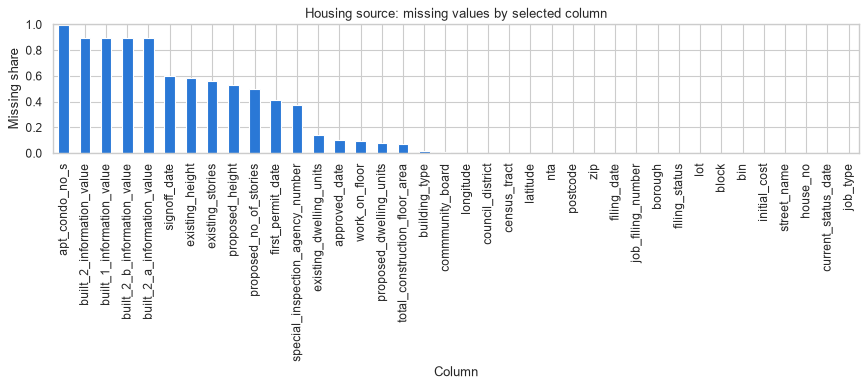

In [29]:
missing = df_raw.isna().mean().sort_values(ascending=False)
display(pd.DataFrame({"missing_count": df_raw.isna().sum(), "missing_share": df_raw.isna().mean()}))
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Duplicate filing IDs:", df_raw.duplicated("job_filing_number").sum())
display(df_raw.select_dtypes(include="number").describe().T)
fig, ax = plt.subplots(figsize=(11, 5))
missing.plot.bar(ax=ax, color="#2a78d6")
ax.set(title="Housing source: missing values by selected column", xlabel="Column", ylabel="Missing share")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

### Initial geography, time and outliers
A log-scaled cost distribution makes the long right tail readable; it is not evidence that every expensive project is erroneous.

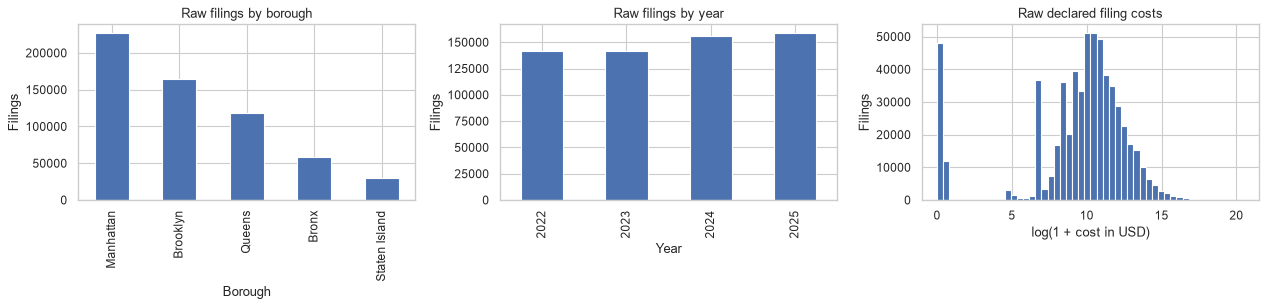

In [30]:
dates = pd.to_datetime(df_raw["filing_date"], format="mixed", errors="coerce")
raw_cost = pd.to_numeric(df_raw["initial_cost"], errors="coerce")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df_raw["borough"].value_counts().plot.bar(ax=axes[0])
axes[0].set(title="Raw filings by borough", xlabel="Borough", ylabel="Filings")
dates.dt.year.value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set(title="Raw filings by year", xlabel="Year", ylabel="Filings")
axes[2].hist(np.log1p(raw_cost[raw_cost >= 0]), bins=50)
axes[2].set(title="Raw declared filing costs", xlabel="log(1 + cost in USD)", ylabel="Filings")
plt.tight_layout()
plt.show()

## 4. Pre-integration cleaning: drop versus impute
1. **Drop** completely empty rows, unusable filing IDs, invalid dates/out-of-window years and invalid boroughs: these cannot be assigned reliable integration keys. Keep the latest status snapshot per filing ID. Drop borough/job-prefix conflicts because their location is ambiguous.
2. **Drop optional columns above 60% missing**, while protecting analysis fields even if sparse. No invented heights, units or costs.
3. **Keep the filing, quarantine the measure:** negative costs/areas, heights outside 0-2,000 feet, stories outside 0-150, and non-integer/negative dwelling units become missing. Unit values over **10,000 per job** are a conservative screening rule, not a verified correction; they become missing for review. In particular, a repeated-digit value such as 111,111,111 cannot dominate housing totals. Large plausible costs/areas/units remain and receive log-scale IQR flags.
4. **Missing existing units are not zero.** A blank does not prove a new building. Use the actual `job_type == "New Building"` label for new-building filing counts.
5. **Official building `postcode` first.** For missing/invalid postcode only, use the existing nearest-SIRTA-crash ZIP method within 0.01 degrees and flag it `nearest_crash`. This distance is approximate and is not an official boundary lookup. Invalid coordinates become missing. Drop rows only if neither method supplies a ZIP. The owner `zip` is never used.

The table below reports the actual rows and decisions. Geographic ZIP validity uses a broad NYC numeric screening range, not a USPS directory. Nearest-crash assignments may create coverage bias and boundary error; no unverified percentage is treated as measured accuracy.

In [31]:
from housing_pipeline import clean_housing, aggregate_housing
df_housing, cleaning_log = clean_housing(df_raw, CLEAN_DIR / "transport_clean_row_level.csv")
display(cleaning_log)
display(df_housing["zip_assignment_method"].value_counts().to_frame("filings"))
display(df_housing[["unit_value_quarantined", "outlier_flag"]].sum().to_frame("filings"))

ZIP assigned to 20.4% of filings (673 left missing).


,step,rows,note
0,Raw,598706,"Complete 2022-2025 download, not a row-limited..."
1,Keys and duplicates,598631,Drop invalid IDs/dates/boroughs; keep latest s...
2,Sparse optional columns,598631,Drop >60% missing optional columns: ['apt_cond...
3,Invalid measures,598631,Keep filings; set impossible measures to NaN. ...
4,Location consistency,598607,Drop borough/job-prefix conflicts; invalid coo...
5,Building ZIP,597934,Official postcode first; 173 flagged approxima...
6,Outliers,597934,Keep high but plausible values and flag using ...


,filings
zip_assignment_method,
official_postcode,597761
nearest_crash,173


,filings
unit_value_quarantined,22
outlier_flag,12162


## 5. Cleaning validation
Compare before/after counts and unit distributions. Keep extreme plausible projects visible, and confirm the filing key and location formats.

,metric,before,after
0,Rows,598706,597934
1,Duplicate filing IDs,55,0
2,Missing proposed units,48703,48662


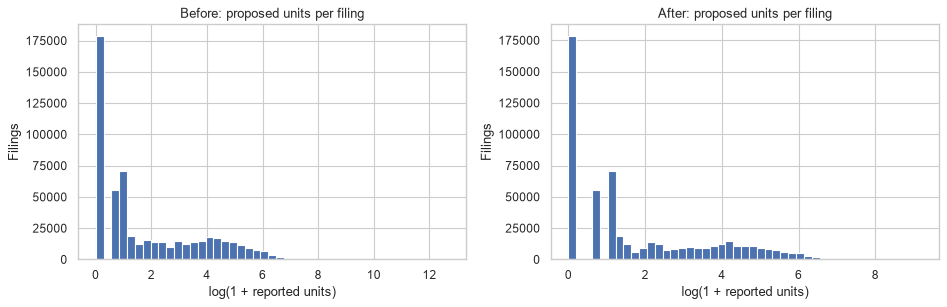

In [32]:
display(pd.DataFrame({
    "metric": ["Rows", "Duplicate filing IDs", "Missing proposed units"],
    "before": [len(df_raw), df_raw.duplicated("job_filing_number").sum(), df_raw["proposed_dwelling_units"].isna().sum()],
    "after": [len(df_housing), df_housing.duplicated("job_filing_number").sum(), df_housing["proposed_dwelling_units"].isna().sum()],
}))
assert not df_housing["job_filing_number"].duplicated().any()
assert df_housing["zip_code"].str.fullmatch(r"\d{5}").all()
assert df_housing["year"].isin([2022, 2023, 2024, 2025]).all()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, data, label in [(axes[0], df_raw, "Before"), (axes[1], df_housing, "After")]:
    values = pd.to_numeric(data["proposed_dwelling_units"], errors="coerce").dropna()
    ax.hist(values.clip(lower=0).pipe(np.log1p), bins=45)
    ax.set(title=f"{label}: proposed units per filing", xlabel="log(1 + reported units)", ylabel="Filings")
plt.tight_layout()
plt.show()

## 6. Aggregate to ZIP code x year without double-counting jobs
`filing_count` counts distinct filing IDs, including amendments. Unit totals must not count the same building-unit report once for every amendment.

Extract the base `job_id` before the filing suffix. Each job contributes **one complete existing/proposed unit pair**, taken from its latest valid filing in this window. Attribute that pair to the ZIP and year of its **first observed filing in 2022-2025**. This is a window-defined job cohort, not necessarily its original lifetime filing year. A job with no complete pair remains unknown; we do not borrow one side from another filing or invent zero units. Negative net changes are allowed.

`unique_job_count` and `jobs_with_known_units` reveal coverage. ZIP-years with no first-observed jobs have zero cohort units; if jobs exist but none report a complete pair, totals stay missing. Partial sums cover reporting jobs only. These are reported job/building-unit quantities, **not completed housing supply**. The four-year job totals can be summed without counting a job twice.

Declared cost and floor-area totals remain **filing-level reported amounts**, which may overlap across related filings; they are not a unique investment total. Official/approximate ZIP counts remain available for sensitivity checks.

In [33]:
df_housing_agg, housing_jobs = aggregate_housing(df_housing)
assert df_housing_agg["filing_count"].sum() == len(df_housing)
assert df_housing_agg["unique_job_count"].sum() == df_housing["job_id"].nunique()
assert df_housing_agg["official_zip_filings"].add(df_housing_agg["approximate_zip_filings"]).equals(df_housing_agg["filing_count"])
df_housing.to_csv(CLEAN_DIR / "housing_clean_row_level.csv", index=False)
df_housing_agg.to_csv(CLEAN_DIR / "housing_clean.csv", index=False)
print(f"Saved housing_clean.csv: {len(df_housing_agg):,} ZIP-years, {df_housing_agg.shape[1]} columns")
print(f"Unique jobs: {len(housing_jobs):,}; complete reported unit pairs: {housing_jobs['proposed_dwelling_units'].notna().sum():,}")
display(df_housing_agg.head())
display(df_housing_agg.dtypes.to_frame("dtype"))

Saved housing_clean.csv: 877 ZIP-years, 23 columns
Unique jobs: 346,294; complete reported unit pairs: 298,176


,zip_code,year,borough,filing_count,new_construction_filings,permit_issued_count,initial_cost_total,initial_cost_median,total_floor_area,avg_proposed_stories,avg_proposed_height,avg_latitude,avg_longitude,outlier_filing_count,outlier_filing_share,official_zip_filings,approximate_zip_filings,unique_job_count,jobs_with_known_units,proposed_units_total,existing_units_total,net_new_units,is_outlier_zip_year
0,10001,2022,MANHATTAN,2659,9,1260,1.118761e+09,25000.00,9.350611e+07,22.886898,288.375479,40.749995,-73.995301,93,0.034976,2659,0,2182,1939,103971.0,96716.0,7255.0,True
1,10001,2023,MANHATTAN,2567,18,1124,1.762834e+09,34999.44,6.568540e+07,25.262959,353.155556,40.750120,-73.995315,93,0.036229,2567,0,1641,1392,71383.0,70768.0,615.0,True
2,10001,2024,MANHATTAN,2650,8,1201,1.146879e+09,38748.50,5.963017e+07,31.220197,461.863192,40.750026,-73.995652,64,0.024151,2650,0,1469,1188,42551.0,41235.0,1316.0,True
3,10001,2025,MANHATTAN,2532,33,833,1.210055e+09,36750.00,4.061151e+07,25.937788,369.956911,40.749856,-73.995030,45,0.017773,2532,0,1372,1107,42749.0,41515.0,1234.0,True
4,10002,2022,MANHATTAN,1334,35,598,3.446611e+08,17500.00,1.192265e+08,10.789077,105.637450,40.717120,-73.988388,66,0.049475,1334,0,1050,996,96736.0,93937.0,2799.0,False


,dtype
zip_code,str
year,int64
borough,string
filing_count,int64
new_construction_filings,Int64
permit_issued_count,int64
initial_cost_total,float64
initial_cost_median,float64
total_floor_area,float64
avg_proposed_stories,float64


## 7. Two research questions and two visualizations
For this member's exploratory charts only, merge the corrected housing aggregate with transportation **in memory**. Never overwrite Member 3's final integrated CSV. Housing-only rows have zero recorded serious crashes under the same coverage assumption documented by Member 3.

### RQ1. How does reported net unit change among first-observed jobs vary by borough and cohort year?
A diverging heatmap distinguishes reported increases from decreases. It does not show homes built.

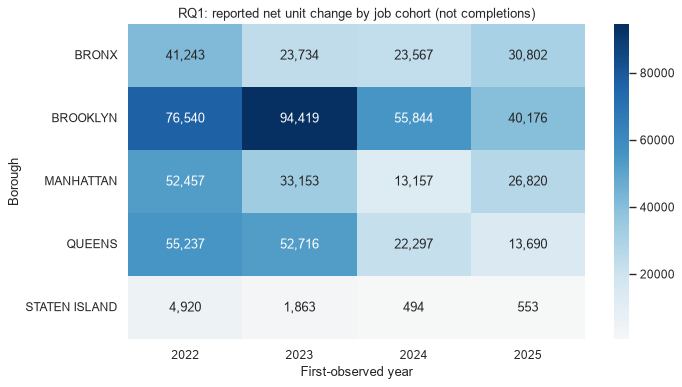

**Finding:** reporting jobs show net change of **663,682 units** across the window. Only **298,176 of 346,294 jobs** have a complete pair. Read the borough-year cells alongside this coverage; incomplete reporting prevents a total-supply claim.

In [34]:
transport_for_housing = pd.read_csv(CLEAN_DIR / "transport_clean.csv", dtype={"zip_code": str})
housing_analysis = df_housing_agg.merge(
    transport_for_housing[["zip_code", "year", "crash_count"]],
    on=["zip_code", "year"], how="left", validate="one_to_one")
housing_analysis["crash_count"] = housing_analysis["crash_count"].fillna(0)
unit_story = (housing_analysis.groupby(["borough", "year"])["net_new_units"]
              .sum(min_count=1).unstack())
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(unit_story, annot=True, fmt=",.0f", center=0, cmap="RdBu", ax=ax)
ax.set(title="RQ1: reported net unit change by job cohort (not completions)", xlabel="First-observed year", ylabel="Borough")
plt.tight_layout()
plt.show()
known = int(housing_jobs["proposed_dwelling_units"].notna().sum())
display(Markdown(f"**Finding:** reporting jobs show net change of **{housing_jobs['net_new_units'].sum():,.0f} units** across the window. "
                 f"Only **{known:,} of {len(housing_jobs):,} jobs** have a complete pair. "
                 "Read the borough-year cells alongside this coverage; incomplete reporting prevents a total-supply claim."))

### RQ2. Are ZIP-years with more housing filings also those with more recorded serious crashes?
A scatter plot shows both counts without treating filings as completed construction. Repeated ZIP-years are not independent; report descriptive correlation rather than an inferential p-value.

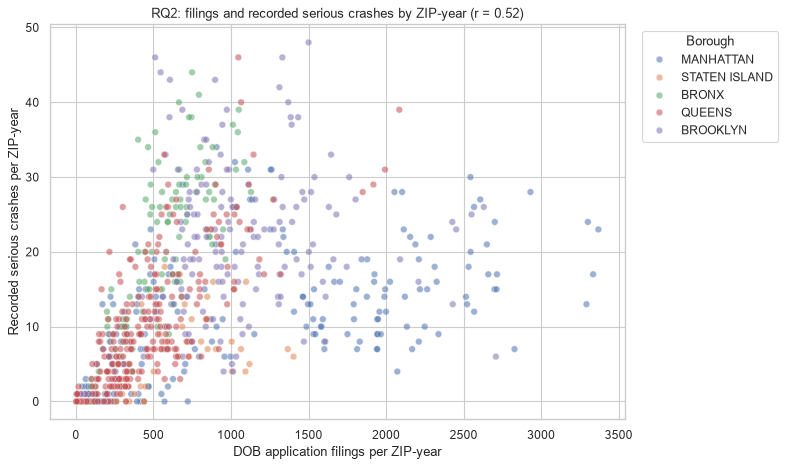

**Finding:** the pooled descriptive Pearson correlation is **0.52**. This compares places of different size and activity. It cannot show that filings cause crashes. Member 3 separately checks changes within places and a one-year lag.

In [35]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=housing_analysis, x="filing_count", y="crash_count", hue="borough", alpha=0.55, ax=ax)
housing_r = housing_analysis["filing_count"].corr(housing_analysis["crash_count"])
ax.set(title=f"RQ2: filings and recorded serious crashes by ZIP-year (r = {housing_r:.2f})",
       xlabel="DOB application filings per ZIP-year", ylabel="Recorded serious crashes per ZIP-year")
ax.legend(title="Borough", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
display(Markdown(f"**Finding:** the pooled descriptive Pearson correlation is **{housing_r:.2f}**. "
                 "This compares places of different size and activity. It cannot show that filings cause crashes. "
                 "Member 3 separately checks changes within places and a one-year lag."))

## 8. Provenance, limitations and contribution
Sources: [H5 housing](https://data.cityofnewyork.us/resource/w9ak-ipjd.json), [T4 SIRTA](https://data.cityofnewyork.us/resource/xeqp-qz8h.json).

Limitations: mutable source snapshots; missing unit pairs; cohort attribution is first observed within this window, not lifetime start; filings and reported units are not completions; approximate ZIP fallback can misclassify boundaries and preferentially cover crash locations; no population/traffic exposure; serious-crash coverage only; correlation is not causation.

Member 1 provides housing EDA, justified cleaning, job-aware unit accounting and two charts. AI-assisted correction and validation are recorded in `docs/prompts.md`; original team members should review the regenerated results before submission.

## Part C - Member 3: integration and research
Only this section writes the authoritative integrated CSV.

# Data Engineering & Visualization - Milestone 1
## Member 3 - Data Integration: Housing (H5) x Transportation (T4)

**Course:** Data Engineering and Visualization, Winter 2026 - GIU
**Team member:** Member 3 (Aya Sweed) - Data integration
**Output of this notebook:** `data/clean/integrated_dataset.csv`: one row per **ZIP code x year (2022-2025)** combining construction activity (Member 1) and serious crashes (Member 2), ready for analysis (Member 4) and the website (Member 5).

**Contents**
1. Inputs, outputs and goal
2. Choosing the integration level (why ZIP code x year)
3. Loading both cleaned files and checking the join keys
4. Merging the datasets (outer join) and reporting the match
5. Post-integration cleaning
6. Derived columns
7. Validation and export
8. Research questions and visualizations (Member 3)
9. Prompts

## 1. Inputs, outputs and goal
Use the corrected housing and transportation aggregates. This is the **only notebook that writes `integrated_dataset.csv`**. Housing uses official building postcode first, with flagged nearest-crash fallback. Units are counted once per base job and attributed to first observation in the 2022-2025 window; unknown unit pairs remain unknown.

Outputs are ZIP-year records and descriptive analyses, not evidence of completed housing or causal road-safety effects. Exact row counts and reconciliation are computed below rather than assumed.

## 2. Why ZIP code x year?
Both sources have geographic identifiers and dates, but no shared individual-record ID. A record-level join would create a meaningless many-to-many product. Borough x year gives only 20 rows and conceals local variation. ZIP x year is interpretable and provides more observations while matching the available geographic quality.

A spatial join or monthly grid could be more precise only with authoritative boundaries, reliable timing and additional work. ZIP boundaries are coarse, can cross administrative boundaries, and nearest-crash fallback can be wrong. Official housing postcode is preferred. Four years are short; filing time is not construction/completion time.

In [36]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "members").is_dir(), "Run from the repository root or notebooks directory."
CLEAN_DIR = ROOT / "data" / "clean"
RAW_DIR = ROOT / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "members" / "member1_housing"))
sys.path.insert(0, str(ROOT / "members" / "member3_integration"))
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.max_columns", 50)

import os
HOUSING_CSV = CLEAN_DIR / "housing_clean.csv"
TRANSPORT_CSV = CLEAN_DIR / "transport_clean.csv"
OUTPUT_CSV = CLEAN_DIR / "integrated_dataset.csv"
KEYS = ["zip_code", "year"]
YEARS = [2022, 2023, 2024, 2025]
BOROUGHS = ["BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"]

## 3. Loading both cleaned files and checking the join keys

A merge is only correct if the keys mean exactly the same thing in both files. Before joining, we check the data contract on **both** sides:

1. `zip_code` is read as **text**, not a number. Read as a number, a ZIP like `"07001"` would lose its leading zero and could silently fail to match. Every value must be exactly 5 digits.
2. `year` is an integer in 2022-2025 in both files. A year stored as `2022.0` in one file and `2022` in the other would not match.
3. The pair (`zip_code`, `year`) is **unique** in each file. If it were not, the merge would multiply rows (one housing row x two crash rows = two output rows) and inflate every total.
4. `borough` uses the same five uppercase labels in both files, because we compare the two `borough` columns after the merge.

Each check is an `assert`, so the notebook stops immediately if a future version of an input file breaks the contract.

In [37]:
housing = pd.read_csv(HOUSING_CSV, dtype={"zip_code": str})
transport = pd.read_csv(TRANSPORT_CSV, dtype={"zip_code": str})

for name, df in [("housing", housing), ("transport", transport)]:
    print(f"{name:10s}: {df.shape[0]:,} rows x {df.shape[1]} columns, "
          f"{df['zip_code'].nunique()} ZIP codes, years {sorted(df['year'].unique().tolist())}")

print("\nHousing columns  :", list(housing.columns))
print("Transport columns:", list(transport.columns))

housing   : 877 rows x 23 columns, 221 ZIP codes, years [2022, 2023, 2024, 2025]
transport : 702 rows x 15 columns, 185 ZIP codes, years [2022, 2023, 2024, 2025]

Housing columns  : ['zip_code', 'year', 'borough', 'filing_count', 'new_construction_filings', 'permit_issued_count', 'initial_cost_total', 'initial_cost_median', 'total_floor_area', 'avg_proposed_stories', 'avg_proposed_height', 'avg_latitude', 'avg_longitude', 'outlier_filing_count', 'outlier_filing_share', 'official_zip_filings', 'approximate_zip_filings', 'unique_job_count', 'jobs_with_known_units', 'proposed_units_total', 'existing_units_total', 'net_new_units', 'is_outlier_zip_year']
Transport columns: ['zip_code', 'year', 'borough', 'crash_count', 'severe_injuries_total', 'non_severe_injuries_total', 'fatalities_total', 'fatal_crash_count', 'severe_per_crash', 'night_crash_share', 'night_crash_count', 'crashes_with_known_time', 'avg_latitude', 'avg_longitude', 'is_outlier_zip_year']


Validate key types, time coverage, uniqueness and borough labels before merging.

In [38]:
def check_keys(df, name):
    assert pd.api.types.is_string_dtype(df["zip_code"]), f"{name}: zip_code must be text"
    assert df["zip_code"].str.fullmatch(r"\d{5}").all(), f"{name}: every zip_code must be 5 digits"
    assert df["zip_code"].notna().all(), f"{name}: zip_code has missing values"
    assert pd.api.types.is_integer_dtype(df["year"]), f"{name}: year must be an integer"
    assert df["year"].isin(YEARS).all(), f"{name}: year outside 2022-2025"
    n_dup = int(df.duplicated(KEYS).sum())
    assert n_dup == 0, f"{name}: {n_dup} duplicated (zip_code, year) pairs"
    assert df["borough"].isin(BOROUGHS).all(), f"{name}: unexpected borough label"
    print(f"{name:10s}: all key checks PASSED "
          f"(5-digit text ZIPs, integer years 2022-2025, unique (zip_code, year), uppercase boroughs)")

check_keys(housing, "housing")
check_keys(transport, "transport")

# Rows per year: shows whether either file is missing a year for some ZIP codes
rows_per_year = pd.DataFrame({
    "housing": housing["year"].value_counts().sort_index(),
    "transport": transport["year"].value_counts().sort_index(),
})
rows_per_year.index.name = "year"
rows_per_year

housing   : all key checks PASSED (5-digit text ZIPs, integer years 2022-2025, unique (zip_code, year), uppercase boroughs)
transport : all key checks PASSED (5-digit text ZIPs, integer years 2022-2025, unique (zip_code, year), uppercase boroughs)


,housing,transport
year,,
2022,218,172
2023,220,174
2024,219,179
2025,220,177


List non-key columns shared by both sources so merge suffixes can be resolved explicitly.

In [39]:
# Columns present in both files (other than the keys): these will collide in the merge
shared = sorted((set(housing.columns) & set(transport.columns)) - set(KEYS))
print("Columns in both files besides the keys:", shared)

Columns in both files besides the keys: ['avg_latitude', 'avg_longitude', 'borough', 'is_outlier_zip_year']


**Result.** Both files pass every key check, so they can be merged directly on `zip_code` + `year` without any conversion.

- Neither file has a row for every ZIP code in every year (see the rows-per-year table). A housing ZIP-year is absent when no filing was assigned to it; a transport ZIP-year is absent when **no serious crash was recorded** there, because Member 2 aggregated crash records. This matters in Section 5, where we decide what a missing row means.
- Four columns besides the keys appear in **both** files: `borough`, `avg_latitude`, `avg_longitude`, and `is_outlier_zip_year`. They describe different things in each file (e.g. the centroid of construction filings vs. the centroid of crashes), so they must not be silently merged. They are resolved in Section 5.

## 4. Merging the datasets (outer join) and reporting the match

**Join type: outer.** We keep every ZIP-year that appears in *either* file.
- An **inner** join would keep only ZIP-years present in both files and silently drop the rest. Dropping a ZIP-year with construction but no serious crash would bias the data towards crash-prone places, and that is exactly the relationship we want to study.
- An outer join keeps those rows and lets us decide openly, in Section 5, how to fill the gaps.

`indicator=True` adds a `_merge` column telling us where each row came from (`both`, `left_only` = housing only, `right_only` = transport only). Columns that exist in both files get the suffixes `_housing` / `_transport` so nothing is overwritten.

`validate="one_to_one"` makes pandas raise an error if a key were duplicated in either file, a second guard on top of the checks in Section 3.

In [40]:
merged = pd.merge(
    housing, transport,
    on=KEYS, how="outer",
    suffixes=("_housing", "_transport"),
    indicator=True, validate="one_to_one",
)
merged["match_status"] = merged["_merge"].map({
    "both": "In both files",
    "left_only": "Housing only",
    "right_only": "Transport only",
})
merged = merged.drop(columns="_merge")

print(f"housing rows   : {len(housing):,}")
print(f"transport rows : {len(transport):,}")
print(f"merged rows    : {len(merged):,}  ({merged['zip_code'].nunique()} ZIP codes)\n")
match_counts = merged["match_status"].value_counts().reindex(["In both files", "Housing only", "Transport only"])
print(match_counts.to_string())

# Sanity check: outer join row count = both + housing only + transport only
assert len(merged) == len(housing) + len(transport) - match_counts["In both files"]

housing rows   : 877
transport rows : 702
merged rows    : 881  (222 ZIP codes)

match_status
In both files     698
Housing only      179
Transport only      4


The left panel gives the overall match. The right panel shows only the one-sided rows per year, because the matched bars would hide them. If the one-sided rows were concentrated in a single year, that would point to a coverage gap in one source rather than to geography.

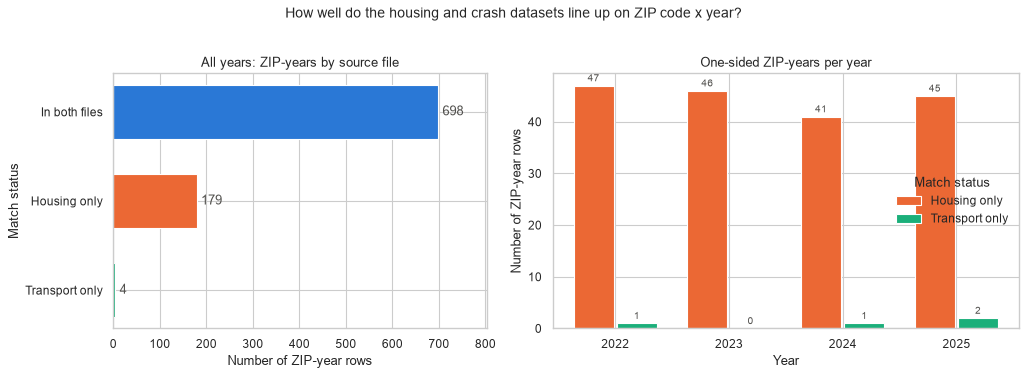

match_status,In both files,Housing only,Transport only
year,,,
2022,171,47,1
2023,174,46,0
2024,178,41,1
2025,175,45,2


In [41]:
# Chart: how well do the two files line up?
STATUS_ORDER = ["In both files", "Housing only", "Transport only"]
STATUS_COLORS = {"In both files": "#2a78d6", "Housing only": "#eb6834", "Transport only": "#1baf7a"}

by_year = (merged.groupby(["year", "match_status"]).size()
           .unstack(fill_value=0).reindex(columns=STATUS_ORDER, fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})

# Left: overall counts
ax = axes[0]
bars = ax.barh(STATUS_ORDER[::-1], match_counts[STATUS_ORDER[::-1]],
               color=[STATUS_COLORS[s] for s in STATUS_ORDER[::-1]], height=0.6)
ax.bar_label(bars, labels=[f"{v:,}" for v in match_counts[STATUS_ORDER[::-1]]], padding=4, color="#52514e")
ax.set_title("All years: ZIP-years by source file")
ax.set_xlabel("Number of ZIP-year rows")
ax.set_ylabel("Match status")
ax.set_xlim(0, match_counts.max() * 1.15)

# Right: the one-sided rows per year (the 'both' bars would dwarf them)
ax = axes[1]
x = np.arange(len(YEARS))
w = 0.38
for i, status in enumerate(["Housing only", "Transport only"]):
    b = ax.bar(x + (i - 0.5) * w, by_year[status].reindex(YEARS, fill_value=0), width=w - 0.03,
               color=STATUS_COLORS[status], label=status)
    ax.bar_label(b, padding=2, color="#52514e", fontsize=9)
ax.set_xticks(x, YEARS)
ax.set_title("One-sided ZIP-years per year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of ZIP-year rows")
ax.legend(title="Match status", frameon=False)

fig.suptitle("How well do the housing and crash datasets line up on ZIP code x year?", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

by_year

Next we list the one-sided ZIP codes and check whether each one is one-sided in **every** year (a ZIP that one source never covers) or only in **some** years (a ZIP-year that simply had no recorded event).

In [42]:
# Which ZIP codes are one-sided, and are they one-sided in every year or only some?
housing_zips, transport_zips = set(housing["zip_code"]), set(transport["zip_code"])
print("ZIP codes only in housing  :", sorted(housing_zips - transport_zips) or "none")
print("ZIP codes only in transport:", sorted(transport_zips - housing_zips) or "none")

one_sided = merged[merged["match_status"] != "In both files"]
summary = (one_sided.groupby(["match_status", "zip_code"])
           .agg(borough=("borough_housing", "first"), years=("year", lambda s: sorted(s.tolist())),
                filing_count=("filing_count", "sum"))
           .reset_index())
summary["borough"] = summary["borough"].fillna(
    summary["zip_code"].map(transport.drop_duplicates("zip_code").set_index("zip_code")["borough"]))
summary

ZIP codes only in housing  : ['10041', '10044', '10055', '10103', '10104', '10105', '10106', '10107', '10110', '10112', '10115', '10118', '10119', '10120', '10121', '10122', '10123', '10151', '10153', '10155', '10158', '10162', '10169', '10171', '10173', '10174', '10175', '10176', '10177', '10178', '10271', '10303', '11005', '11021', '11109', '11359', '11697']
ZIP codes only in transport: ['10111']


,match_status,zip_code,borough,years,filing_count
0,Housing only,10004,MANHATTAN,"[2022, 2023]",877.0
1,Housing only,10005,MANHATTAN,[2025],721.0
2,Housing only,10006,MANHATTAN,"[2022, 2025]",509.0
3,Housing only,10020,MANHATTAN,"[2022, 2023, 2025]",1381.0
4,Housing only,10041,MANHATTAN,"[2022, 2023, 2024, 2025]",140.0
5,Housing only,10044,MANHATTAN,"[2022, 2023, 2024, 2025]",387.0
6,Housing only,10055,MANHATTAN,"[2022, 2023, 2024, 2025]",148.0
7,Housing only,10103,MANHATTAN,"[2022, 2023, 2024, 2025]",251.0
8,Housing only,10104,MANHATTAN,"[2022, 2023, 2024, 2025]",282.0
9,Housing only,10105,MANHATTAN,"[2022, 2023, 2024, 2025]",257.0


### Reading the join audit
Most one-sided rows are **housing only**. The ZIP codes that are housing-only in *every* year are mostly Midtown and Financial District ZIPs assigned to a single large building or complex (for example 10118), plus a few small or edge ZIPs. Official building postcode puts filings in these ZIPs, but a crash on the street outside is recorded under the surrounding street ZIP, so the crash file can never contain them. For these ZIPs a recorded crash count of 0 comes from how ZIP codes are assigned, not from safe streets.

They stay in the integrated file, because their filings are real. Section 8 excludes ZIP codes that never appear in the crash file from the research questions, so they do not add artificial zero-crash points.

Transport-only rows mean housing coverage is unknown, not proof of no development.

## 5. Post-integration cleaning

Merging creates problems that did not exist in either input file. We fix four kinds:

1. **Duplicated columns**: `borough`, `avg_latitude`, `avg_longitude` and `is_outlier_zip_year` now exist twice (`_housing` / `_transport`).
2. **New missing values** created by the outer join: crash columns are empty on the housing-only rows, and housing columns are empty on the transport-only rows (counts in Section 4).
3. **Source flags**: after filling, we must still be able to tell a real value from a filled one.
4. **Data types**: integer count columns became decimals during the merge, because pandas stores missing numbers as `NaN`, which is a float.

We first record the missing values right after the merge, so we can show a before/after table at the end of this section.

In [43]:
integrated = merged.copy()
missing_before = integrated.isna().sum()
print("Columns with missing values right after the merge:")
print(missing_before[missing_before > 0].to_string())

Columns with missing values right after the merge:
borough_housing                    4
filing_count                       4
new_construction_filings           4
permit_issued_count                4
initial_cost_total                 4
initial_cost_median                4
total_floor_area                   6
avg_proposed_stories              12
avg_proposed_height               13
avg_latitude_housing               8
avg_longitude_housing              8
outlier_filing_count               4
outlier_filing_share               4
official_zip_filings               4
approximate_zip_filings            4
unique_job_count                   4
jobs_with_known_units              4
proposed_units_total               5
existing_units_total               5
net_new_units                      5
is_outlier_zip_year_housing        4
borough_transport                179
crash_count                      179
severe_injuries_total            179
non_severe_injuries_total        179
fatalities_total        

### 5.1 Duplicated columns

**`borough`.** We compare the two versions wherever both exist. If they disagreed, the same ZIP code would sit in two boroughs, which would point to a ZIP-assignment error. Then we keep one column, taking the housing value and filling from transport where housing is missing (the transport-only rows).

In [44]:
both_present = integrated["borough_housing"].notna() & integrated["borough_transport"].notna()
conflicts = integrated[both_present & (integrated["borough_housing"] != integrated["borough_transport"])]
print(f"Rows where both files give a borough: {both_present.sum()}")
print(f"Rows where they disagree           : {len(conflicts)}")

assert conflicts.empty, "Resolve source borough conflicts before export."

integrated["borough"] = integrated["borough_housing"].fillna(integrated["borough_transport"])
assert integrated["borough"].isin(BOROUGHS).all()

# A ZIP code must belong to exactly one borough across all years
assert (integrated.groupby("zip_code")["borough"].nunique() == 1).all(), "Resolve ZIP/borough ambiguity before export"
print("Every ZIP code maps to exactly one borough.")

Rows where both files give a borough: 698
Rows where they disagree           : 0
Every ZIP code maps to exactly one borough.


**`avg_latitude` / `avg_longitude`.** These mean different things: the housing pair is the centre of that year's *construction filings*, while the transport pair is the centre of that year's *crashes*. They also move from year to year with wherever activity happened. Keeping four coordinate columns would confuse the people using the file. They are only needed to place a ZIP code on a map (Members 4 and 5), so we replace them with **one fixed point per ZIP code**: `zip_latitude` / `zip_longitude`, the mean of all available housing and crash centroids for that ZIP across all years. This also gives a location to rows where one side is missing. We first measure how far apart the two centres are, to show that averaging them is reasonable.

In [45]:
lat_cols = ["avg_latitude_housing", "avg_latitude_transport"]
lon_cols = ["avg_longitude_housing", "avg_longitude_transport"]

# Distance between filing centre and crash centre in the same ZIP-year (1 degree of latitude ~ 111 km)
dist_km = np.hypot(
    integrated["avg_latitude_housing"] - integrated["avg_latitude_transport"],
    (integrated["avg_longitude_housing"] - integrated["avg_longitude_transport"]) * np.cos(np.radians(40.7)),
) * 111
print(f"Filing centre vs crash centre, same ZIP-year: median {dist_km.median():.2f} km, "
      f"90th percentile {dist_km.quantile(0.9):.2f} km, max {dist_km.max():.2f} km")

long_coords = pd.concat([
    integrated[["zip_code", "avg_latitude_housing", "avg_longitude_housing"]].set_axis(["zip_code", "lat", "lon"], axis=1),
    integrated[["zip_code", "avg_latitude_transport", "avg_longitude_transport"]].set_axis(["zip_code", "lat", "lon"], axis=1),
])
zip_centroids = (long_coords.groupby("zip_code")[["lat", "lon"]].mean().round(6)
                 .rename(columns={"lat": "zip_latitude", "lon": "zip_longitude"}))
integrated = integrated.merge(zip_centroids, on="zip_code", how="left")
assert integrated["zip_latitude"].isna().equals(integrated["zip_longitude"].isna())
missing_map_zips = sorted(integrated.loc[integrated["zip_latitude"].isna(), "zip_code"].unique())
print(f"Descriptive map points for {len(zip_centroids) - len(missing_map_zips)} of {len(zip_centroids)} ZIPs.")
print(f"ZIPs without any source coordinates (retained for non-map analysis): {missing_map_zips}")


Filing centre vs crash centre, same ZIP-year: median 0.27 km, 90th percentile 0.66 km, max 4.50 km
Descriptive map points for 221 of 222 ZIPs.
ZIPs without any source coordinates (retained for non-map analysis): ['10044']


**`is_outlier_zip_year`.** The two flags answer different questions: *unusually many filings* (housing) vs *unusually many crashes* (transport). Both are useful, so we keep both under clear names: `is_outlier_housing` and `is_outlier_transport`. Where a side has no data, there is nothing to be an outlier, so the flag is `False`; the source flags added in 5.3 show that case explicitly.

In [46]:
integrated["is_outlier_housing"] = integrated["is_outlier_zip_year_housing"].fillna(False).astype(bool)
integrated["is_outlier_transport"] = integrated["is_outlier_zip_year_transport"].fillna(False).astype(bool)

integrated = integrated.drop(columns=[
    "borough_housing", "borough_transport",
    "avg_latitude_housing", "avg_latitude_transport", "avg_longitude_housing", "avg_longitude_transport",
    "is_outlier_zip_year_housing", "is_outlier_zip_year_transport",
])
print(integrated["is_outlier_housing"].sum(), "housing outlier rows;",
      integrated["is_outlier_transport"].sum(), "transport outlier rows")

47 housing outlier rows; 4 transport outlier rows


### 5.2 Missing values: structural absence versus unknown measurements
An outer join keeps every source key. A housing-only ZIP-year is assigned zero **recorded** serious crashes under the assumption that the retained crash table has no record there; this is not proof of no crashes outside SIRTA or among excluded rows. Preserve the source flags.

A transport-only row has unknown housing coverage and **must not** be filled with zero filings. Unknown source measures remain missing. Shares are undefined when their denominator is zero. Housing unit totals can also be missing where first-observed jobs have no complete unit pairs; `jobs_with_known_units` exposes partial reporting.

In [47]:
CRASH_COUNTS = ["crash_count", "severe_injuries_total", "non_severe_injuries_total",
                "fatalities_total", "fatal_crash_count", "night_crash_count", "crashes_with_known_time"]
CRASH_RATES = ["severe_per_crash", "night_crash_share"]
housing_only = integrated["match_status"] == "Housing only"
transport_only = integrated["match_status"] == "Transport only"
assert integrated.loc[~housing_only, ["crash_count", "severe_injuries_total"]].notna().all().all()
integrated.loc[housing_only, CRASH_COUNTS] = 0
print(f"Structural zero recorded-crash counts: {housing_only.sum()} housing-only rows.")
print(f"Unknown housing coverage: {transport_only.sum()} transport-only rows.")
display(integrated.isna().sum()[lambda s: s > 0].to_frame("missing"))

Structural zero recorded-crash counts: 179 housing-only rows.
Unknown housing coverage: 4 transport-only rows.


,missing
filing_count,4
new_construction_filings,4
permit_issued_count,4
initial_cost_total,4
initial_cost_median,4
total_floor_area,6
avg_proposed_stories,12
avg_proposed_height,13
outlier_filing_count,4
outlier_filing_share,4


### 5.3 Source flags

Two boolean columns record where each row's data came from, so filled values can always be told apart from observed ones:
- `has_housing_data`: `True` if the housing file had a row for this ZIP-year (`False` on the transport-only rows).
- `has_crash_data`: `True` if the crash file had a row (`False` on the housing-only rows, whose crash counts were set to 0 in 5.2).

They replace the temporary `match_status` column.

In [48]:
integrated["has_housing_data"] = integrated["match_status"] != "Transport only"
integrated["has_crash_data"] = integrated["match_status"] != "Housing only"
integrated = integrated.drop(columns="match_status")

pd.crosstab(integrated["has_housing_data"], integrated["has_crash_data"], margins=True)

has_crash_data,False,True,All
has_housing_data,,,
False,0,4,4
True,179,698,877
All,179,702,881


### 5.4 Data types and column order
Keep text ZIPs and integer years. Nullable integer counts preserve unknown source coverage/measurements without decimal formatting. Coordinates and rates remain numeric; source flags remain boolean. The exported schema preserves provenance and job-unit/time coverage.

In [49]:
HOUSING_COUNTS = ["filing_count", "new_construction_filings", "permit_issued_count", "outlier_filing_count", "official_zip_filings", "approximate_zip_filings", "unique_job_count", "jobs_with_known_units"]
for col in HOUSING_COUNTS:
    integrated[col] = integrated[col].round().astype("Int64")
for col in CRASH_COUNTS:
    integrated[col] = integrated[col].round().astype("Int64")
integrated["zip_code"] = integrated["zip_code"].astype(str)
integrated["year"] = integrated["year"].astype(int)

REPLACED = ["borough", "avg_latitude", "avg_longitude", "is_outlier_zip_year"]
HOUSING_COLS = [c for c in housing.columns if c not in KEYS + REPLACED]
TRANSPORT_COLS = [c for c in transport.columns if c not in KEYS + REPLACED]
ORDER = (KEYS + ["borough", "zip_latitude", "zip_longitude", "has_housing_data", "has_crash_data"]
         + HOUSING_COLS + TRANSPORT_COLS + ["is_outlier_housing", "is_outlier_transport"])
assert set(ORDER) == set(integrated.columns), set(integrated.columns) ^ set(ORDER)
integrated = integrated[ORDER].sort_values(KEYS).reset_index(drop=True)

integrated.dtypes.to_frame("dtype").T

,zip_code,year,borough,zip_latitude,zip_longitude,has_housing_data,has_crash_data,filing_count,new_construction_filings,permit_issued_count,initial_cost_total,initial_cost_median,total_floor_area,avg_proposed_stories,avg_proposed_height,outlier_filing_count,outlier_filing_share,official_zip_filings,approximate_zip_filings,unique_job_count,jobs_with_known_units,proposed_units_total,existing_units_total,net_new_units,crash_count,severe_injuries_total,non_severe_injuries_total,fatalities_total,fatal_crash_count,severe_per_crash,night_crash_share,night_crash_count,crashes_with_known_time,is_outlier_housing,is_outlier_transport
dtype,str,int64,str,float64,float64,bool,bool,Int64,Int64,Int64,float64,float64,float64,float64,float64,Int64,float64,Int64,Int64,Int64,Int64,float64,float64,float64,Int64,Int64,Int64,Int64,Int64,float64,float64,Int64,Int64,bool,bool


### 5.5 Before/after missing values
The table below distinguishes resolved merge gaps from source/reporting gaps. Unknown housing measures, incomplete job unit pairs and undefined rates stay missing. Do not replace all blanks with zero.

In [50]:
missing_after = integrated.isna().sum()
mv = pd.DataFrame({
    "missing_after_merge": missing_before.reindex(integrated.columns).fillna(0),
    "missing_after_cleaning": missing_after,
}).astype(int)
mv = mv[(mv > 0).any(axis=1)]
mv["explanation"] = [
    "Undefined without known-time crashes" if c == "night_crash_share" else
    "Undefined without recorded crashes" if c == "severe_per_crash" else
    "Unknown source measurements, incomplete unit pairs, or no housing coverage; not imputed"
    for c in mv.index
]
display(mv)

,missing_after_merge,missing_after_cleaning,explanation
zip_latitude,0,4,"Unknown source measurements, incomplete unit p..."
zip_longitude,0,4,"Unknown source measurements, incomplete unit p..."
filing_count,4,4,"Unknown source measurements, incomplete unit p..."
new_construction_filings,4,4,"Unknown source measurements, incomplete unit p..."
permit_issued_count,4,4,"Unknown source measurements, incomplete unit p..."
initial_cost_total,4,4,"Unknown source measurements, incomplete unit p..."
initial_cost_median,4,4,"Unknown source measurements, incomplete unit p..."
total_floor_area,6,6,"Unknown source measurements, incomplete unit p..."
avg_proposed_stories,12,12,"Unknown source measurements, incomplete unit p..."
avg_proposed_height,13,13,"Unknown source measurements, incomplete unit p..."


**Result.** After cleaning, the integrated table has one `borough` (no conflicts between the files), one fixed map position per ZIP code, two clearly named outlier flags, and two source flags. Every remaining missing value has a stated reason:
- **Housing columns** are missing on the transport-only rows (`has_housing_data = False`). Unit totals are also missing where no first-observed job reported a complete unit pair.
- **Crash rates** (`severe_per_crash`, `night_crash_share`) are missing on the housing-only rows, where there is no crash to divide by.
- **Average stories/height and floor area** are missing where no filing reported them.
- **Map points** are missing only for ZIP codes with no source coordinates at all.

Nothing was filled with a number we cannot defend.

## 6. Derived measures
- Serious crashes per 100 filings: descriptive ratio between unrelated event types, **not personal risk**. Zero/missing filings produce missing ratios.
- Year-over-year differences: match the same ZIP to the actual preceding calendar year, not previous row order.
- Next-year crashes: match the same ZIP to year + 1; the final year is missing by definition.
- Severe injuries per 1,000 reported proposed units: denominator counts once per first-observed job with a complete unit pair. This is **not injuries per resident or per newly built home** and may be distorted by reporting coverage. It is also unstable where very few units are proposed (1 severe injury over 1 proposed unit scores 1,000), so read it next to `proposed_units_total`.

The corrected unit accounting removes amendment duplication, but does not make the reported units a completion measure.

In [51]:
# 1. Rate: serious crashes per 100 construction filings (Int64 -> float so missing stays NaN)
filings = integrated["filing_count"].astype("float").where(integrated["filing_count"] > 0)
integrated["crashes_per_100_filings"] = (integrated["crash_count"] / filings * 100).round(2)

# 2-3. Year-over-year change, matched on year - 1 (not on row position)
prev = integrated[KEYS + ["filing_count", "crash_count"]].copy()
prev["year"] = prev["year"] + 1                      # last year's values, labelled with this year
prev = prev.rename(columns={"filing_count": "filing_prev", "crash_count": "crash_prev"})
integrated = integrated.merge(prev, on=KEYS, how="left")
integrated["filing_change_yoy"] = (integrated["filing_count"].astype("float") - integrated["filing_prev"].astype("float"))
integrated["crash_change_yoy"] = integrated["crash_count"] - integrated["crash_prev"]

# 4. Next year's crashes, matched on year + 1
nxt = integrated[KEYS + ["crash_count"]].copy()
nxt["year"] = nxt["year"] - 1                        # next year's values, labelled with this year
nxt = nxt.rename(columns={"crash_count": "crashes_next_year"})
integrated = integrated.merge(nxt, on=KEYS, how="left").drop(columns=["filing_prev", "crash_prev"])

# 5. Descriptive only: severe injuries per 1,000 proposed dwelling units (0 units -> undefined)
units = integrated["proposed_units_total"].where(integrated["proposed_units_total"] > 0)
integrated["severe_injuries_per_1000_units"] = (integrated["severe_injuries_total"] / units * 1000).round(3)

# Whole-number columns keep a nullable integer type
for col in ["filing_change_yoy", "crash_change_yoy", "crashes_next_year"]:
    integrated[col] = integrated[col].round().astype("Int64")

DERIVED = ["crashes_per_100_filings", "filing_change_yoy", "crash_change_yoy",
           "crashes_next_year", "severe_injuries_per_1000_units"]
integrated[DERIVED].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
crashes_per_100_filings,877.0,1.89,2.1,0.0,0.5,1.49,2.74,33.33
filing_change_yoy,655.0,26.13,96.87,-491.0,-23.0,11.0,64.0,435.0
crash_change_yoy,657.0,0.36,5.36,-20.0,-2.0,0.0,3.0,21.0
crashes_next_year,657.0,12.23,10.95,0.0,2.0,10.0,20.0,48.0
severe_injuries_per_1000_units,747.0,9.76,45.02,0.0,0.4,1.72,5.24,1000.0


Check that each derived column is blank exactly where it should be: lag columns only where the neighbouring calendar year exists for the same ZIP, crashes per 100 filings only where filings are known, and no infinite ratios.

In [52]:
previous_keys = set(zip(integrated["zip_code"], integrated["year"]))
has_previous = pd.Series([(z, y - 1) in previous_keys for z, y in zip(integrated["zip_code"], integrated["year"])])
has_next = pd.Series([(z, y + 1) in previous_keys for z, y in zip(integrated["zip_code"], integrated["year"])])
assert integrated["crashes_next_year"].notna().equals(has_next)
assert integrated["crash_change_yoy"].notna().equals(has_previous)
assert integrated.loc[~integrated["has_housing_data"], "crashes_per_100_filings"].isna().all()
assert not np.isinf(integrated[DERIVED].astype(float).to_numpy()).any()
display(integrated[DERIVED].isna().sum().to_frame("missing"))

,missing
crashes_per_100_filings,4
filing_change_yoy,226
crash_change_yoy,224
crashes_next_year,224
severe_injuries_per_1000_units,134


A worked example on one ZIP code, so the lag and rate columns can be checked by hand.

In [53]:
# Example: one ZIP code over the four years, to check the derived columns by eye
integrated.loc[integrated["zip_code"] == "11207",
               KEYS + ["filing_count", "crash_count", "severe_injuries_total", "proposed_units_total"] + DERIVED]

,zip_code,year,filing_count,crash_count,severe_injuries_total,proposed_units_total,crashes_per_100_filings,filing_change_yoy,crash_change_yoy,crashes_next_year,severe_injuries_per_1000_units
533,11207,2022,1312,42,40,26534.0,3.2,<NA>,<NA>,38,1.507
534,11207,2023,1385,38,38,19562.0,2.74,73,-4,48,1.943
535,11207,2024,1500,48,46,10509.0,3.2,115,10,28,4.377
536,11207,2025,1516,28,27,8120.0,1.85,16,-20,<NA>,3.325


### Derived-column interpretation
Checks match actual neighboring calendar keys, so a missing year is not mistaken for an adjacent one. The final year's next-year crashes remain unknown. Job-unit ratios use the corrected, once-per-job reports, but still do not represent risk per resident or completed home. Inspect ZIP 11207 as a worked example.

## 7. Validate and export
Check the union of input keys, unique ZIP-years, integer years, geographic formats, source-presence flags, and reconciliation of all count/unit/cost measures. Do not hard-code a snapshot row count: public data and official ZIP coverage can change.

In [54]:
source_keys = set(map(tuple, housing[KEYS].to_numpy())) | set(map(tuple, transport[KEYS].to_numpy()))
assert set(map(tuple, integrated[KEYS].to_numpy())) == source_keys
assert len(integrated) == len(source_keys)
assert not integrated.duplicated(KEYS).any()
recon = []
for col in ["filing_count", "unique_job_count", "jobs_with_known_units", "new_construction_filings",
            "permit_issued_count", "proposed_units_total", "existing_units_total", "net_new_units",
            "official_zip_filings", "approximate_zip_filings", "initial_cost_total"]:
    recon.append((col, "housing", housing[col].sum(), integrated[col].sum()))
for col in CRASH_COUNTS:
    recon.append((col, "transport", transport[col].sum(), integrated[col].sum()))
recon = pd.DataFrame(recon, columns=["column", "source_file", "source_total", "integrated_total"])
recon["match"] = np.isclose(recon["source_total"].astype(float), recon["integrated_total"].astype(float))
assert recon["match"].all(), "Totals changed during integration."
check_keys(integrated, "integrated")
assert all(c == c.lower() and " " not in c for c in integrated.columns)
assert integrated["jobs_with_known_units"].le(integrated["unique_job_count"]).fillna(True).all()
print(f"Validated {len(integrated):,} ZIP-years, {integrated.shape[1]} columns.")
display(recon)

integrated: all key checks PASSED (5-digit text ZIPs, integer years 2022-2025, unique (zip_code, year), uppercase boroughs)
Validated 881 ZIP-years, 40 columns.


,column,source_file,source_total,integrated_total,match
0,filing_count,housing,5.979340e+05,5.979340e+05,True
1,unique_job_count,housing,3.462940e+05,3.462940e+05,True
2,jobs_with_known_units,housing,2.981760e+05,2.981760e+05,True
3,new_construction_filings,housing,4.037900e+04,4.037900e+04,True
4,permit_issued_count,housing,2.337800e+05,2.337800e+05,True
5,proposed_units_total,housing,1.263380e+07,1.263380e+07,True
6,existing_units_total,housing,1.197012e+07,1.197012e+07,True
7,net_new_units,housing,6.636820e+05,6.636820e+05,True
8,official_zip_filings,housing,5.977610e+05,5.977610e+05,True
9,approximate_zip_filings,housing,1.730000e+02,1.730000e+02,True


Describe every exported column for the analysis and website handoff.

In [55]:
# Column summary (data dictionary for Members 4 and 5)
DESCRIPTIONS = {
    "official_zip_filings": "filings assigned using official building postcode",
    "approximate_zip_filings": "filings assigned by flagged nearest-crash fallback",
    "unique_job_count": "base jobs first observed in this ZIP-year within 2022-2025",
    "jobs_with_known_units": "first-observed jobs with a complete reported unit pair",
    "night_crash_count": "known-time crashes in hours 00-05 or 22-23",
    "crashes_with_known_time": "crashes with a usable time; nighttime-share denominator",
    "zip_code": "5-digit ZIP code (text)", "year": "calendar year 2022-2025",
    "borough": "NYC borough (uppercase)",
    "zip_latitude": "descriptive map point from source means; blank when no source coordinates exist",
    "zip_longitude": "fixed map point of the ZIP (see zip_latitude)",
    "has_housing_data": "False = no housing source row; housing columns remain unknown",
    "has_crash_data": "False = no serious crash recorded; crash counts filled with 0",
    "filing_count": "construction job filings (H5) in the ZIP-year",
    "new_construction_filings": "filings labelled New Building in source job_type",
    "permit_issued_count": "filings that reached permit issued / LOC issued",
    "proposed_units_total": "reported proposed units counted once per first-observed job with complete pair",
    "existing_units_total": "reported existing units from the same complete job pairs",
    "net_new_units": "job-cohort proposed minus existing reported units; not completions",
    "initial_cost_total": "sum of declared filing costs, USD; related filings may overlap",
    "initial_cost_median": "median declared job cost, USD",
    "total_floor_area": "sum of construction floor area, sq ft",
    "avg_proposed_stories": "mean proposed stories (filings that report it)",
    "avg_proposed_height": "mean proposed height, ft (filings that report it)",
    "outlier_filing_count": "filings flagged as outliers by Member 1",
    "outlier_filing_share": "share of filings flagged as outliers",
    "crash_count": "serious-injury crashes (SIRTA, T4)",
    "severe_injuries_total": "people seriously injured",
    "non_severe_injuries_total": "people with non-serious injuries in those crashes",
    "fatalities_total": "people killed",
    "fatal_crash_count": "crashes with at least one death",
    "severe_per_crash": "serious injuries per crash (blank if 0 crashes)",
    "night_crash_share": "share of crashes at night (blank if 0 crashes)",
    "is_outlier_housing": "unusually high filing_count (Member 1's IQR flag)",
    "is_outlier_transport": "unusually high crash_count (Member 2's IQR flag)",
    "crashes_per_100_filings": "crash_count / filing_count x 100",
    "filing_change_yoy": "filing_count minus previous year (blank in first year)",
    "crash_change_yoy": "crash_count minus previous year (blank in first year)",
    "crashes_next_year": "crash_count of the same ZIP in year + 1 (blank for 2025)",
    "severe_injuries_per_1000_units": "descriptive ratio per 1,000 reported job-cohort proposed units, not resident risk",
}
assert set(DESCRIPTIONS) == set(integrated.columns), set(DESCRIPTIONS) ^ set(integrated.columns)
column_summary = pd.DataFrame({
    "dtype": integrated.dtypes.astype(str),
    "missing": integrated.isna().sum(),
    "example (ZIP 11207, 2023)": integrated[(integrated["zip_code"] == "11207") & (integrated["year"] == 2023)].iloc[0].astype(str),
    "description": pd.Series(DESCRIPTIONS),
})
column_summary

,dtype,missing,"example (ZIP 11207, 2023)",description
approximate_zip_filings,Int64,4,0,filings assigned by flagged nearest-crash fall...
avg_proposed_height,float64,13,45.50301204819277,"mean proposed height, ft (filings that report it)"
avg_proposed_stories,float64,12,4.396914446002805,mean proposed stories (filings that report it)
borough,str,0,BROOKLYN,NYC borough (uppercase)
crash_change_yoy,Int64,224,-4,crash_count minus previous year (blank in firs...
crash_count,Int64,0,38,"serious-injury crashes (SIRTA, T4)"
crashes_next_year,Int64,224,48,crash_count of the same ZIP in year + 1 (blank...
crashes_per_100_filings,Float64,4,2.74,crash_count / filing_count x 100
crashes_with_known_time,Int64,0,38,crashes with a usable time; nighttime-share de...
existing_units_total,float64,5,14893.0,reported existing units from the same complete...


Save and reload the authoritative integrated table, then verify the exported key formats.

In [56]:
integrated.to_csv(OUTPUT_CSV, index=False, encoding="utf-8")

# Read the saved file back exactly as Members 4 and 5 will
reloaded = pd.read_csv(OUTPUT_CSV, dtype={"zip_code": str})
check_keys(reloaded, "reloaded CSV")
assert reloaded.shape == integrated.shape
print(f"Saved {OUTPUT_CSV}: {reloaded.shape[0]} rows x {reloaded.shape[1]} columns "
      f"({os.path.getsize(OUTPUT_CSV) / 1024:.0f} KB)")
print("Load it with: pd.read_csv('data/clean/integrated_dataset.csv', dtype={'zip_code': str})")

reloaded CSV: all key checks PASSED (5-digit text ZIPs, integer years 2022-2025, unique (zip_code, year), uppercase boroughs)
Saved C:\Users\voxic\AppData\Local\Temp\claude\C--MyFolders-Third-Year-Data-Engineering-and-Visualization-Project1-nyc-housing-transport\6b92afad-d7ee-4cee-b40b-237e692938d9\scratchpad\m3fix\data\clean\integrated_dataset.csv: 881 rows x 40 columns (211 KB)
Load it with: pd.read_csv('data/clean/integrated_dataset.csv', dtype={'zip_code': str})


### Export result
The saved/reloaded file above is authoritative. Its current dimensions and source reconciliations are computed, not hard-coded. Re-run after source changes and keep notebook outputs/CSVs synchronized.

## 8. Research questions and visualizations (Member 3)

Both questions use the **integrated** dataset: they need construction and crash data side by side, so neither could be answered from one input file alone.

**Why not just correlate filings with crashes?** Across ZIP codes, busy places have more of everything: more people, traffic, buildings, filings *and* crashes. A raw "more filings, more crashes" correlation mostly measures ZIP size, not any link between construction and road safety. Both questions below therefore compare each ZIP code **with itself over time**, which removes the fixed differences in size between ZIP codes.

### 8.1 Research question 1

> **RQ1: Did ZIP codes whose construction activity grew the most between 2022 and 2025 also see a larger change in serious crashes?**

- **Measure:** for each ZIP code, the change in `filing_count` from 2022 to 2025 against the change in `crash_count` over the same years.
- **Rows used:** ZIP codes with known housing data at both endpoints that appear in the crash file in at least one year (Section 4 explains why ZIPs the crash file can never cover are left out). The actual count is printed below.
- **Statistics:** Pearson r (linear) and Spearman rho (rank-based, less sensitive to a few extreme ZIP codes), each with its p-value.

In [57]:
from scipy import stats

BOROUGH_COLORS = {"BRONX": "#2a78d6", "BROOKLYN": "#eb6834", "MANHATTAN": "#1baf7a",
                  "QUEENS": "#eda100", "STATEN ISLAND": "#e87ba4"}

# ZIP codes that appear in the crash file in at least one year (see Section 4)
crash_zips = set(integrated.loc[integrated["has_crash_data"], "zip_code"])
never_in_crash_file = sorted(set(integrated["zip_code"]) - crash_zips)
print(f"Excluded {len(never_in_crash_file)} ZIP codes that never appear in the crash file: {never_in_crash_file}")

wide = (integrated[integrated["has_housing_data"] & integrated["zip_code"].isin(crash_zips)]
        .pivot(index="zip_code", columns="year", values=["filing_count", "crash_count"]).astype(float))
rq1 = pd.DataFrame({
    "filing_change": wide[("filing_count", 2025)] - wide[("filing_count", 2022)],
    "crash_change": wide[("crash_count", 2025)] - wide[("crash_count", 2022)],
    "crashes_2022": wide[("crash_count", 2022)],
}).dropna()
rq1["borough"] = rq1.index.map(integrated.drop_duplicates("zip_code").set_index("zip_code")["borough"])

r, p_r = stats.pearsonr(rq1["filing_change"], rq1["crash_change"])
rho, p_rho = stats.spearmanr(rq1["filing_change"], rq1["crash_change"])
print(f"ZIP codes used: {len(rq1)}")
print(f"Change in filings 2022->2025: median {rq1['filing_change'].median():+.0f} (range {rq1['filing_change'].min():+.0f} to {rq1['filing_change'].max():+.0f})")
print(f"Change in crashes 2022->2025: median {rq1['crash_change'].median():+.0f} (range {rq1['crash_change'].min():+.0f} to {rq1['crash_change'].max():+.0f})")
print(f"Pearson r = {r:.3f} (p = {p_r:.2f});  Spearman rho = {rho:.3f} (p = {p_rho:.2f})")

# Check: is crash change just regression to the mean (high-crash ZIPs falling back)?
print(f"Correlation of crash change with 2022 crash level: {rq1['crash_change'].corr(rq1['crashes_2022']):.2f}")

by_boro = rq1.groupby("borough").apply(lambda g: pd.Series({
    "zip_codes": len(g), "median_filing_change": g["filing_change"].median(),
    "median_crash_change": g["crash_change"].median(),
    "pearson_r": g["filing_change"].corr(g["crash_change"])})).round(2)
by_boro

Excluded 37 ZIP codes that never appear in the crash file: ['10041', '10044', '10055', '10103', '10104', '10105', '10106', '10107', '10110', '10112', '10115', '10118', '10119', '10120', '10121', '10122', '10123', '10151', '10153', '10155', '10158', '10162', '10169', '10171', '10173', '10174', '10175', '10176', '10177', '10178', '10271', '10303', '11005', '11021', '11109', '11359', '11697']
ZIP codes used: 183
Change in filings 2022->2025: median +77 (range -295 to +592)
Change in crashes 2022->2025: median +1 (range -20 to +30)
Pearson r = -0.069 (p = 0.35);  Spearman rho = -0.084 (p = 0.26)
Correlation of crash change with 2022 crash level: -0.25


,zip_codes,median_filing_change,median_crash_change,pearson_r
borough,,,,
BRONX,25.0,111.0,-1.0,0.30
BROOKLYN,39.0,122.0,3.0,0.02
MANHATTAN,48.0,20.5,0.5,-0.27
QUEENS,60.0,71.0,2.0,-0.15
STATEN ISLAND,11.0,204.0,1.0,-0.32


The scatter plot shows one point per ZIP code, coloured by borough. If construction growth went with crash growth, the points would rise from bottom left to top right along the dashed trend line.

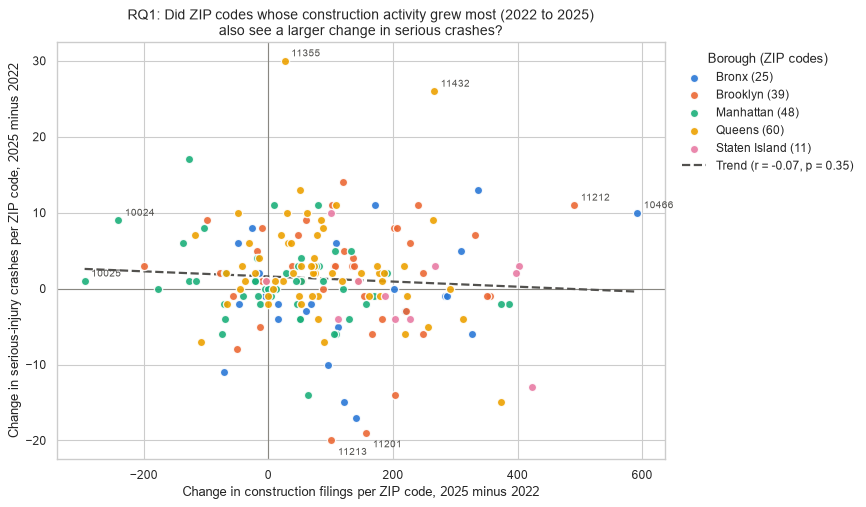

In [58]:
fig, ax = plt.subplots(figsize=(11, 6.5))

for boro in BOROUGHS:
    g = rq1[rq1["borough"] == boro]
    ax.scatter(g["filing_change"], g["crash_change"], s=55, color=BOROUGH_COLORS[boro],
               edgecolor="white", linewidth=1.2, alpha=0.9, label=f"{boro.title()} ({len(g)})", zorder=3)

# Least-squares trend line over all ZIP codes
slope, intercept = np.polyfit(rq1["filing_change"], rq1["crash_change"], 1)
xs = np.linspace(rq1["filing_change"].min(), rq1["filing_change"].max(), 100)
ax.plot(xs, slope * xs + intercept, color="#52514e", linewidth=2, linestyle="--", zorder=2,
        label=f"Trend (r = {r:.2f}, p = {p_r:.2f})")

ax.axhline(0, color="#898781", linewidth=1, zorder=1)
ax.axvline(0, color="#898781", linewidth=1, zorder=1)

# Label only the most extreme ZIP codes on each axis
to_label = set(rq1["filing_change"].nlargest(2).index) | set(rq1["filing_change"].nsmallest(2).index) \
         | set(rq1["crash_change"].nlargest(2).index) | set(rq1["crash_change"].nsmallest(2).index)
for z in to_label:
    ax.annotate(z, (rq1.loc[z, "filing_change"], rq1.loc[z, "crash_change"]),
                xytext=(6, -13 if rq1.loc[z, "crash_change"] < 0 else 4), textcoords="offset points",
                fontsize=9, color="#52514e")

ax.set_title("RQ1: Did ZIP codes whose construction activity grew most (2022 to 2025)\n"
             "also see a larger change in serious crashes?", fontsize=13)
ax.set_xlabel("Change in construction filings per ZIP code, 2025 minus 2022")
ax.set_ylabel("Change in serious-injury crashes per ZIP code, 2025 minus 2022")
ax.legend(title="Borough (ZIP codes)", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**RQ1 interpretation.** The calculated finding below states the direction and strength of the association between each ZIP code's 2022-to-2025 change in filings and its change in serious crashes. The p-values assume independent ZIP codes; neighbouring ZIPs are not independent, and this is one of several exploratory comparisons, so they are only a rough guide.

The result cannot separate construction from changes in population, traffic, reporting or anything else. Four years and two endpoints are limited, and regression to the mean affects change scores (ZIP codes with many crashes in 2022 tend to fall back). No claim that construction is safe or harmful is warranted.

In [59]:
def describe_strength(value):
    size = abs(value)
    if size < 0.1:
        return "no meaningful"
    label = "a weak" if size < 0.3 else "a moderate" if size < 0.5 else "a strong"
    return f"{label} {'positive' if value > 0 else 'negative'}"

display(Markdown(
    f"**Calculated RQ1 finding:** across {len(rq1):,} ZIP codes, the change in filings from 2022 to 2025 shows "
    f"**{describe_strength(r)} linear relationship** with the change in serious crashes "
    f"(Pearson r = {r:.2f}, p = {p_r:.2f}; Spearman rho = {rho:.2f}, p = {p_rho:.2f}). "
    "ZIP codes where construction grew most did not reliably see larger crash changes. "
    "This is a descriptive association, not a construction effect."
    if abs(r) < 0.1 else
    f"**Calculated RQ1 finding:** across {len(rq1):,} ZIP codes, the change in filings from 2022 to 2025 shows "
    f"**{describe_strength(r)} linear relationship** with the change in serious crashes "
    f"(Pearson r = {r:.2f}, p = {p_r:.2f}; Spearman rho = {rho:.2f}, p = {p_rho:.2f}). "
    "This is a descriptive association, not a construction effect."))

**Calculated RQ1 finding:** across 183 ZIP codes, the change in filings from 2022 to 2025 shows **no meaningful linear relationship** with the change in serious crashes (Pearson r = -0.07, p = 0.35; Spearman rho = -0.08, p = 0.26). ZIP codes where construction grew most did not reliably see larger crash changes. This is a descriptive association, not a construction effect.

### 8.2 Research question 2

> **RQ2: Is a ZIP code's construction activity in one year associated with its serious crashes in the following year?**

If construction affected road safety (e.g. through work zones, trucks, or blocked sidewalks), the effect might show up with a delay, as projects move from filing to work on site. RQ1 compared only the two end years; RQ2 uses **every pair of consecutive years** (2022→2023, 2023→2024, 2024→2025).

- **Rows used:** ZIP-years with housing data and a known next year, in ZIP codes that appear in the crash file (2025 has no next year). The count is printed below.
- **Two views of the same data:**
  1. **Between ZIP codes:** do ZIP-years with more filings have more crashes the next year? This is the naive comparison, and it mixes in ZIP size.
  2. **Within each ZIP code:** in years when a ZIP had *more filings than its own average*, did it have *more crashes than its own average* the next year? Subtracting each ZIP's own average removes size, density and every other fixed difference between ZIP codes.
- **Extra check:** a small regression of next-year crashes on this year's filings *and* this year's crashes, to see whether filings add anything once we know a ZIP's current crash level.

In [60]:
rq2 = integrated[integrated["has_housing_data"] & integrated["crashes_next_year"].notna()
                 & integrated["zip_code"].isin(crash_zips)].copy()
rq2["filing_count"] = rq2["filing_count"].astype(float)
rq2["crashes_next_year"] = rq2["crashes_next_year"].astype(float)
print(f"Rows used: {len(rq2)} ZIP-years ({rq2['zip_code'].nunique()} ZIP codes x years {sorted(rq2['year'].unique().tolist())})\n")

# View 1: between ZIP codes
r_b, p_b = stats.pearsonr(rq2["filing_count"], rq2["crashes_next_year"])
rho_b, p_rho_b = stats.spearmanr(rq2["filing_count"], rq2["crashes_next_year"])
print(f"Pooled ZIP-years (descriptive): Pearson r = {r_b:.2f}, Spearman rho = {rho_b:.2f}")

# View 2: within each ZIP code (deviation from the ZIP's own 2022-2024 average)
rq2["filing_dev"] = rq2["filing_count"] - rq2.groupby("zip_code")["filing_count"].transform("mean")
rq2["crash_next_dev"] = rq2["crashes_next_year"] - rq2.groupby("zip_code")["crashes_next_year"].transform("mean")
r_w, p_w = stats.pearsonr(rq2["filing_dev"], rq2["crash_next_dev"])
print(f"Within-ZIP deviations (descriptive): Pearson r = {r_w:.2f}; repeated ZIP-years, no independence-based p-value")

# Extra check: next-year crashes ~ this year's filings + this year's crashes (ordinary least squares)
X = np.column_stack([np.ones(len(rq2)), rq2["filing_count"], rq2["crash_count"]])
coef, *_ = np.linalg.lstsq(X, rq2["crashes_next_year"], rcond=None)
print(f"\nRegression: next-year crashes = {coef[0]:.2f} + {coef[1]:.4f} x filings + {coef[2]:.2f} x this year's crashes")
print(f"-> 100 extra filings go with {coef[1] * 100:+.2f} serious crashes next year, once this year's crashes are known")

# Quartiles describe volume groups, not treatment groups.
rq2["filing_quartile"] = pd.qcut(rq2["filing_count"], 4, labels=["Q1 (fewest)", "Q2", "Q3", "Q4 (most)"])
rq2["dev_quartile"] = pd.qcut(rq2["filing_dev"], 4, labels=["Much below\nown average", "Below", "Above", "Much above\nown average"])
summary_between = rq2.groupby("filing_quartile", observed=True).agg(
    filings_range=("filing_count", lambda s: f"{s.min():.0f}-{s.max():.0f}"),
    median_crashes_next_year=("crashes_next_year", "median"), rows=("zip_code", "size"))
summary_within = rq2.groupby("dev_quartile", observed=True).agg(
    median_crash_next_dev=("crash_next_dev", "median"), mean_crash_next_dev=("crash_next_dev", "mean"),
    rows=("zip_code", "size")).round(2)
display(summary_between)
display(summary_within)

Rows used: 550 ZIP-years (184 ZIP codes x years [2022, 2023, 2024])

Pooled ZIP-years (descriptive): Pearson r = 0.40, Spearman rho = 0.61
Within-ZIP deviations (descriptive): Pearson r = 0.06; repeated ZIP-years, no independence-based p-value

Regression: next-year crashes = 1.87 + 0.0014 x filings + 0.82 x this year's crashes
-> 100 extra filings go with +0.14 serious crashes next year, once this year's crashes are known


,filings_range,median_crashes_next_year,rows
filing_quartile,,,
Q1 (fewest),1-326,4.0,138
Q2,327-606,12.0,137
Q3,610-1009,19.0,137
Q4 (most),1013-3369,19.0,138


,median_crash_next_dev,mean_crash_next_dev,rows
dev_quartile,,,
Much below\nown average,-0.67,-0.64,138
Below,0.33,0.54,140
Above,-0.33,-0.31,134
Much above\nown average,0.33,0.40,138


Panel A compares ZIP-years with each other, which mixes in ZIP size. Panel B compares each ZIP code with its own average, which removes fixed size differences. A real lagged link would show boxes rising from left to right in **both** panels.

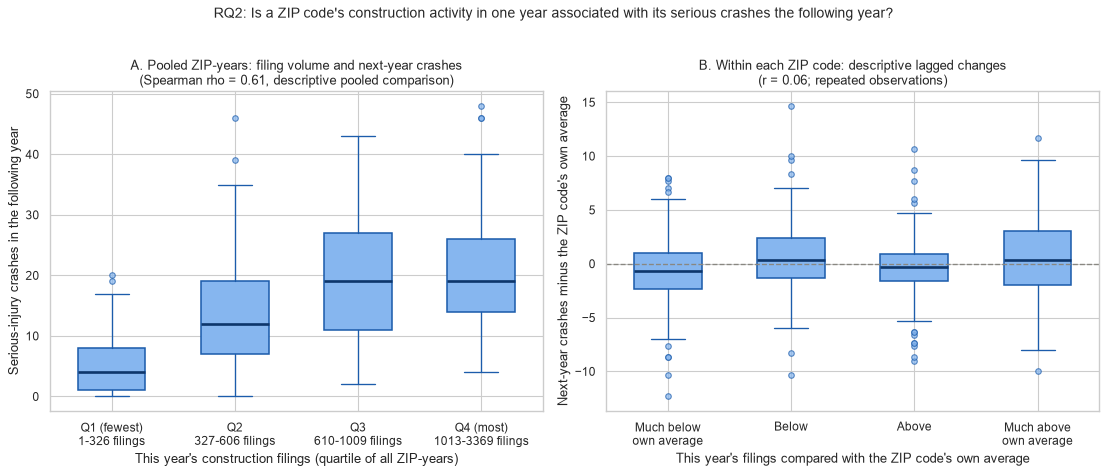

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))
box_style = dict(patch_artist=True, widths=0.55, showfliers=True,
                 boxprops=dict(facecolor="#86b6ef", edgecolor="#1c5cab", linewidth=1.4),
                 medianprops=dict(color="#0d366b", linewidth=2.4),
                 whiskerprops=dict(color="#1c5cab", linewidth=1.2), capprops=dict(color="#1c5cab", linewidth=1.2),
                 flierprops=dict(marker="o", markersize=5, markerfacecolor="#86b6ef", markeredgecolor="#1c5cab", alpha=0.7))

# Panel A: between ZIP codes
cats_a = rq2["filing_quartile"].cat.categories
axes[0].boxplot([rq2.loc[rq2["filing_quartile"] == c, "crashes_next_year"] for c in cats_a], **box_style)
axes[0].set_xticks(range(1, 5), [f"{c}\n{summary_between.loc[c, 'filings_range']} filings" for c in cats_a])
axes[0].set_title(f"A. Pooled ZIP-years: filing volume and next-year crashes\n"
                  f"(Spearman rho = {rho_b:.2f}, descriptive pooled comparison)", fontsize=11.5)
axes[0].set_xlabel("This year's construction filings (quartile of all ZIP-years)")
axes[0].set_ylabel("Serious-injury crashes in the following year")

# Panel B: within each ZIP code
cats_b = rq2["dev_quartile"].cat.categories
axes[1].boxplot([rq2.loc[rq2["dev_quartile"] == c, "crash_next_dev"] for c in cats_b], **box_style)
axes[1].axhline(0, color="#898781", linewidth=1.2, linestyle="--")
axes[1].set_xticks(range(1, 5), cats_b)
axes[1].set_title(f"B. Within each ZIP code: descriptive lagged changes\n"
                  f"(r = {r_w:.2f}; repeated observations)", fontsize=11.5)
axes[1].set_xlabel("This year's filings compared with the ZIP code's own average")
axes[1].set_ylabel("Next-year crashes minus the ZIP code's own average")

fig.suptitle("RQ2: Is a ZIP code's construction activity in one year associated with its serious crashes the following year?",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

**RQ2 interpretation:** compare the pooled between-place correlation to the within-ZIP deviations printed above. A pooled association does not establish a within-place change. The rows contain repeated ZIPs; ordinary independence-based p-values do **not** account for clustering, so they are not reported for this repeated-observation analysis. The regression is descriptive, not a causal model.

Potential confounders include traffic volume, population, density and land use, none of which are measured here. Three consecutive-year pairs per ZIP are too few to rule out small effects or alternative lags. Filing dates are not dates of work on site. Official postcode reduces—but does not eliminate—geographic uncertainty.

In [62]:
if r_b >= 0.3 and abs(r_w) < 0.1:
    reading = ("The between-ZIP association largely disappears within ZIP codes: busier ZIP codes have both more "
               "filings and more crashes, but a ZIP's above-average filing years are not followed by above-average "
               "crash years. This points to ZIP size and activity level, not a year-to-year construction link.")
else:
    reading = "Compare the two views before drawing any conclusion; neither is a causal estimate."
display(Markdown(
    f"**Calculated RQ2 finding:** {len(rq2):,} ZIP-years in {rq2['zip_code'].nunique()} ZIP codes. "
    f"Between ZIP codes: Pearson r = **{r_b:.2f}**, Spearman rho = **{rho_b:.2f}**. "
    f"Within each ZIP code: r = **{r_w:.2f}**. Once this year's crashes are known, 100 extra filings go with "
    f"**{coef[1] * 100:+.2f}** serious crashes the next year. {reading} "
    "Repeated observations and unmeasured exposure prevent causal interpretation."))

**Calculated RQ2 finding:** 550 ZIP-years in 184 ZIP codes. Between ZIP codes: Pearson r = **0.40**, Spearman rho = **0.61**. Within each ZIP code: r = **0.06**. Once this year's crashes are known, 100 extra filings go with **+0.14** serious crashes the next year. The between-ZIP association largely disappears within ZIP codes: busier ZIP codes have both more filings and more crashes, but a ZIP's above-average filing years are not followed by above-average crash years. This points to ZIP size and activity level, not a year-to-year construction link. Repeated observations and unmeasured exposure prevent causal interpretation.

## 9. Prompts

An AI assistant (Claude) was used to help write and debug the code in this notebook; every result was run and reviewed by the author (Aya Sweed, Member 3). The same list is kept in `docs/prompts.md`. Each entry gives the prompt and, in brackets, what was checked.

These record the original development pass and its old snapshot counts, **not the current regenerated results**. The correction request and approved methodology are in `docs/prompts.md`.

1. Check whether the housing data Member 1 used is the real H5 table, and download the full dataset for 2022-2025. (found the local snapshot was an 18,500-row sample with columns that don't exist in H5; wrote `members/member3_integration/fetch_h5_data.py`, which downloaded 598,706 rows)
2. Re-run Member 1's housing notebook on the real data and fix any errors. (fixed the import path for `assign_zip_from_sirta`, a pandas 3 dtype check, and domain checks 4a/4b, which were dropping 316,671 filings with blank height or units; checked that only 633 rows are now removed and that `housing_clean.csv` has 736 rows = 184 ZIPs x 4 years)
3. What exactly should Member 1 fix after the regeneration? (list: dwelling units double-counted across filings of the same job, an uncaught 111,111,111 typo, markdown cells written about the old sample)
4. Draft a task-based plan for my integration work that I can approve step by step. (tasks: key checks, outer merge, post-integration cleaning, derived columns, validation/export, 2 research questions)
5. Create the integration notebook with its goal, inputs/outputs, and a markdown section explaining why we join on ZIP code x year and which alternatives we rejected. (reviewed the reasoning: record level not allowed, borough x year only 20 rows, spatial join and monthly grain considered; noted the nearest-crash ZIP assignment as a limitation)
6. Load both cleaned files and check the join keys before merging: 5-digit text ZIP codes, integer years 2022-2025, unique (zip_code, year) pairs, uppercase boroughs. (all checks passed: housing 736 rows / 184 ZIPs, transport 703 rows / 185 ZIPs; found 4 columns present in both files to resolve after the merge)
7. Merge the two files with an outer join on zip_code + year, chart how many ZIP-years matched / are housing-only / transport-only, and list the one-sided ZIP codes. (738 rows: 701 matched, 35 housing-only, 2 transport-only; checked that every housing-only ZIP has crashes in other years and that the transport-only ZIP 10282 has no filings because of nearest-crash ZIP assignment)
8. Do the post-integration cleaning: resolve the duplicated columns, fill the missing values created by the join, add source flags, and fix data types. For ZIP 10282 (no housing row), use a flag instead of filling filing_count with 0. (0 borough conflicts; replaced 4 coordinate columns with one centroid per ZIP; crash counts set to 0 on 35 housing-only rows but crash rates left blank; added has_housing_data / has_crash_data; checked the before/after missing-value table)
9. Add derived columns: crashes per 100 filings, year-over-year change in filings and crashes, next-year crashes, and severe injuries per 1,000 units (marked provisional until Member 1's unit fix). (year links matched on year +/- 1, not row order; checked each column is blank only where it should be, e.g. crashes_next_year blank for 2025; verified ZIP 11207 by hand)
10. Validate the integrated table and export integrated_dataset.csv: row count, unique keys, totals matching the source files, data contract, plus a column summary for Members 4 and 5. (738 rows x 34 columns; all filing and crash totals equal the source files; re-read the saved CSV to confirm ZIP codes stay 5-digit text)
11. Research question 1: did ZIP codes whose construction activity grew most between 2022 and 2025 also see a larger change in serious crashes? Make a scatter chart with title, axis labels and trend line. (184 ZIP codes; no relationship, Pearson r = -0.07, p = 0.37; checked regression to the mean and per-borough results; wrote limitations, no causal claims)
12. Research question 2: is a ZIP code's construction activity in one year associated with its serious crashes the following year? Compare between ZIP codes and within each ZIP code, with a two-panel box-plot chart. (552 ZIP-years; between ZIP codes Spearman rho = 0.63, within ZIP codes r = 0.04, p = 0.37; regression: 100 extra filings go with +0.14 crashes next year; interpreted as a ZIP-size effect, not a construction effect)
13. Review my prompt log, add a prompts section to the notebook, and draft my 2-3 line contribution entry for the README. (checked the wording and added my name)
14. Check Pierre's correction PRs and finish my integration fixes now that Member 1's work is merged: update the notebook text to the regenerated data, remove the old provisional wording, and keep ZIP codes that never appear in the crash file out of the research questions. (checked against the live API that H5 does have a building postcode; replaced stale hard-coded counts and placeholder markdown; re-ran the notebook, all key and total checks pass)

## Part D - Member 2: completed cross-domain research
The preceding integration is now available, so these charts run on the refreshed data.

## 7. Two research questions and visualizations
Run Member 3 first to refresh the integrated data. Read the actual shared path and agreed columns; there are no placeholder metrics.

**RQ1:** Across ZIP-years, how is filing activity associated with the number of people seriously injured in recorded crashes? A scatter plot shows counts, not individual risk.

**RQ2:** Does the observed nighttime crash share differ across filing-volume groups within each borough? A heatmap uses nighttime counts divided by **known-time crash counts**, not an unweighted mean of ZIP percentages. Filing groups are descriptive quartiles, not causal treatments.

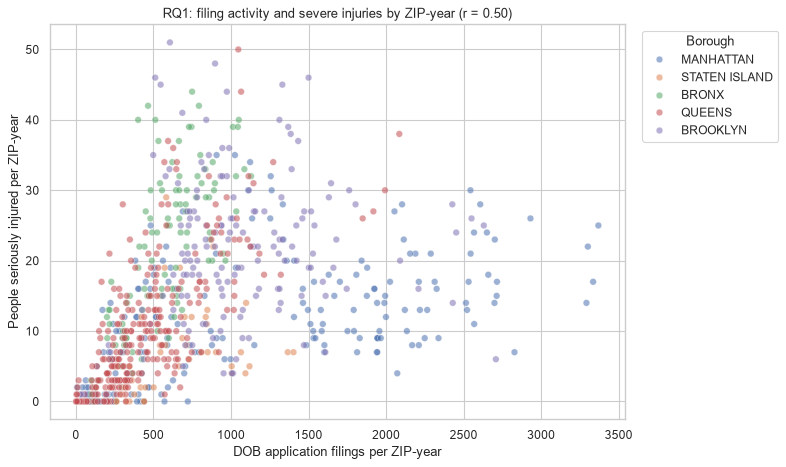

**RQ1 finding:** pooled Pearson r = **0.50**. This descriptive association may reflect ZIP size/traffic; repeated ZIP-years are not independent, so no independence-based p-value or causal claim is made.

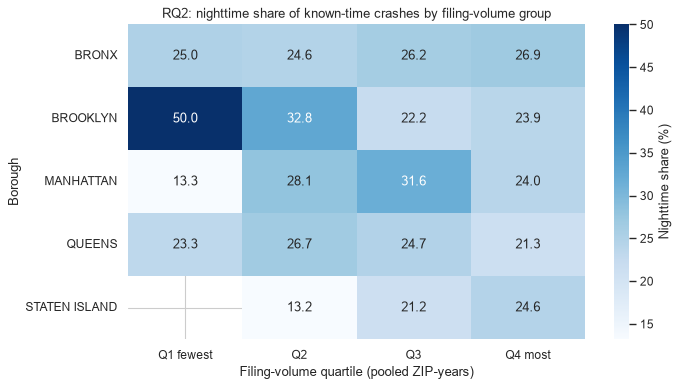

**RQ2 finding:** observed shares range from **13.2% to 50.0%** across borough/quartile cells with known-time crashes. Blank cells have no usable denominator. Quartiles mix years and differently sized ZIPs; the pattern is not evidence that development changes nighttime risk.

night_crash_count  crashes_with_known_time  \
borough       filing_quartile                                               
BRONX         Q1 fewest                       11                       44   
              Q2                             122                      495   
              Q3                             345                     1319   
              Q4 most                         73                      271   
BROOKLYN      Q1 fewest                        2                        4   
              Q2                              45                      137   
              Q3                             289                     1300   
              Q4 most                        448                     1872   
MANHATTAN     Q1 fewest                        6                       45   
              Q2                              94                      334   
              Q3                              87                      275   
              Q4 most                        361                     1505   
QUEENS        Q1 fewest                       31                      133   
              Q2                             254                      953   
              Q3                             230                      930   
              Q4 most                        123                      578   
STATEN ISLAND Q2                               7                       53   
              Q3                              47                      222   
              Q4 most                         14                       57   

                               night_share  
borough       filing_quartile               
BRONX         Q1 fewest           0.250000  
              Q2                  0.246465  
              Q3                  0.261562  
              Q4 most             0.269373  
BROOKLYN      Q1 fewest           0.500000  
              Q2                  0.328467  
              Q3                  0.222308  
              Q4 most             0.239316  
MANHATTAN     Q1 fewest           0.133333  
              Q2                  0.281437  
              Q3                  0.316364  
              Q4 most             0.239867  
QUEENS        Q1 fewest           0.233083  
              Q2                  0.266527  
              Q3                  0.247312  
              Q4 most             0.212803  
STATEN ISLAND Q2                  0.132075  
              Q3                  0.211712  
              Q4 most             0.245614

In [63]:
df_merged = pd.read_csv(CLEAN_DIR / "integrated_dataset.csv", dtype={"zip_code": str})
analysis_transport = df_merged.loc[df_merged["has_housing_data"] & df_merged["filing_count"].notna()].copy()
assert not analysis_transport.empty, "No integrated housing rows for analysis."
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=analysis_transport, x="filing_count", y="severe_injuries_total",
                hue="borough", alpha=0.55, ax=ax)
transport_r = analysis_transport["filing_count"].corr(analysis_transport["severe_injuries_total"])
ax.set(title=f"RQ1: filing activity and severe injuries by ZIP-year (r = {transport_r:.2f})",
       xlabel="DOB application filings per ZIP-year", ylabel="People seriously injured per ZIP-year")
ax.legend(title="Borough", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
display(Markdown(f"**RQ1 finding:** pooled Pearson r = **{transport_r:.2f}**. "
                 "This descriptive association may reflect ZIP size/traffic; repeated ZIP-years are not independent, "
                 "so no independence-based p-value or causal claim is made."))

analysis_transport["filing_quartile"] = pd.qcut(
    analysis_transport["filing_count"].rank(method="min", pct=True),
    [0, .25, .5, .75, 1], labels=["Q1 fewest", "Q2", "Q3", "Q4 most"])
night_summary = analysis_transport.groupby(["borough", "filing_quartile"], observed=True)[
    ["night_crash_count", "crashes_with_known_time"]].sum()
night_summary["night_share"] = night_summary["night_crash_count"] / night_summary["crashes_with_known_time"].replace(0, np.nan)
pivot = night_summary["night_share"].unstack()
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(pivot * 100, annot=True, fmt=".1f", cmap="Blues", ax=ax, cbar_kws={"label": "Nighttime share (%)"})
ax.set(title="RQ2: nighttime share of known-time crashes by filing-volume group",
       xlabel="Filing-volume quartile (pooled ZIP-years)", ylabel="Borough")
plt.tight_layout()
plt.show()
valid_night = night_summary["night_share"].dropna()
assert not valid_night.empty
display(Markdown(f"**RQ2 finding:** observed shares range from **{valid_night.min():.1%} to {valid_night.max():.1%}** "
                 "across borough/quartile cells with known-time crashes. Blank cells have no usable denominator. "
                 "Quartiles mix years and differently sized ZIPs; the pattern is not evidence that development changes nighttime risk."))
display(night_summary)

### Interpretation and limitations
The findings above are calculated from the regenerated data. Serious crashes are a selected subset; missing ZIPs/time affect coverage; nearest-neighbor ZIP recovery is approximate; population and traffic exposure are absent; severity classifications can lag. Counts and nighttime shares do not measure residents' individual risk, and correlation is not causation.

## 8. Prompts used, links, and contribution

### 8.1 Dataset links
- **Transportation (T4, SIRTA):** https://data.cityofnewyork.us/Transportation/Serious-Injury-Response-Tracking-Analysis-Program-/xeqp-qz8h
- **Housing (Member 1):** [DOB NOW Build Job Application Filings](https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd)
- **Dataset catalog / project description:** provided by the course (Dr. Nada Sharaf, TAs).

### 8.2 Prompts used (required by the project)
Record **every** prompt used in this part, with the step it supported:

| # | Step | Prompt (summary) |
|---|---|---|
| 1 | Planning | Asked an AI assistant to review the 5-member task division and timeline against the project requirements. |
| 2 | Dataset choice | Asked which transportation dataset from the catalog best integrates with a housing dataset (ZIP × year); chose T4/SIRTA (`xeqp-qz8h`). |
| 3 | Loading | Asked for code to download the dataset with the NYC Open Data API (`$limit`, `$order`) and a fallback to a local CSV. |
| 4 | Notebook | Asked an AI assistant to build the Member 2 notebook (overview, EDA, pre-integration cleaning, aggregation, research questions) using the SIRTA data dictionary, satisfying every grading requirement. |

*(Add any later prompts here, e.g. for debugging or chart design.)*

### 8.3 Member 2 contribution (copy to the README)
- Selected and documented the transportation dataset (SIRTA, T4) and justified the choice.
- Performed EDA (structure, missing values, duplicates, inconsistencies, distributions).
- Pre-integration cleaning: duplicates, format standardization (dates, borough, 5-digit ZIP), domain-rule checks, ZIP recovery from coordinates, outlier flagging (IQR), validation plots.
- Aggregated the data to ZIP × year and delivered `transport_clean.csv` per the data contract.
- Executed 2 research questions and 2 visualizations (Section 7).

## Part E - Member 4: analysis and storytelling
### RQ1. Do the boroughs accounting for the most filing activity also account for the most recorded serious crashes?
Compare each borough's **share of the same four-year totals**, rather than overlaying differently scaled raw counts. Keep unmatched source rows in the totals; report housing coverage separately. Shares are event distributions, not population-adjusted risk.

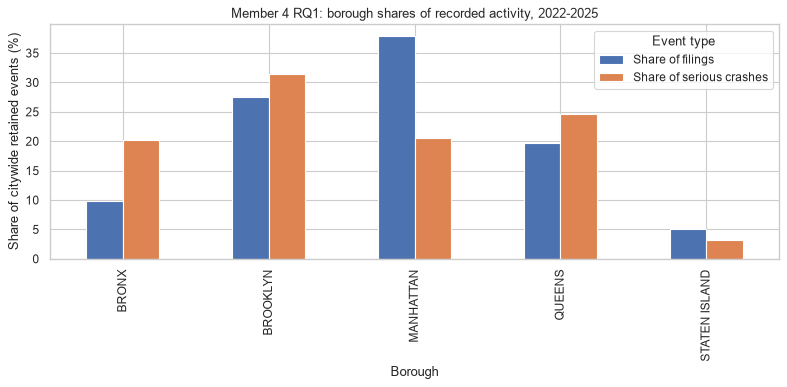

**Finding:** **Manhattan** has the largest filing share (**38.0%**); **Brooklyn** has the largest serious-crash share (**31.5%**). Differences describe the geographic distribution of retained events, not differences in individual danger.

,filing_count,crash_count
borough,,
BRONX,58487.0,2129
BROOKLYN,164165.0,3313
MANHATTAN,226991.0,2163
QUEENS,117931.0,2594
STATEN ISLAND,30360.0,332


In [64]:
story = pd.read_csv(CLEAN_DIR / "integrated_dataset.csv", dtype={"zip_code": str})
borough_totals = story.groupby("borough")[["filing_count", "crash_count"]].sum(min_count=1)
borough_shares = borough_totals.div(borough_totals.sum(), axis=1) * 100
fig, ax = plt.subplots(figsize=(10, 5))
borough_shares.rename(columns={"filing_count": "Share of filings", "crash_count": "Share of serious crashes"}).plot.bar(ax=ax)
ax.set(title="Member 4 RQ1: borough shares of recorded activity, 2022-2025",
       xlabel="Borough", ylabel="Share of citywide retained events (%)")
ax.legend(title="Event type")
plt.tight_layout()
plt.show()
filing_leader = borough_totals["filing_count"].idxmax()
crash_leader = borough_totals["crash_count"].idxmax()
display(Markdown(f"**Finding:** **{filing_leader.title()}** has the largest filing share "
                 f"(**{borough_shares.loc[filing_leader, 'filing_count']:.1f}%**); "
                 f"**{crash_leader.title()}** has the largest serious-crash share "
                 f"(**{borough_shares.loc[crash_leader, 'crash_count']:.1f}%**). "
                 "Differences describe the geographic distribution of retained events, not differences in individual danger."))
display(borough_totals)

### RQ2. How have filing activity and recorded serious crashes changed relative to their 2022 levels within a consistent ZIP panel?
Use ZIPs with housing coverage in **all four years**. Keep structural zero recorded-crash counts, but do not turn missing housing coverage into zero. Index each event series independently to 2022 = 100. Separate aligned panels avoid a misleading dual axis.

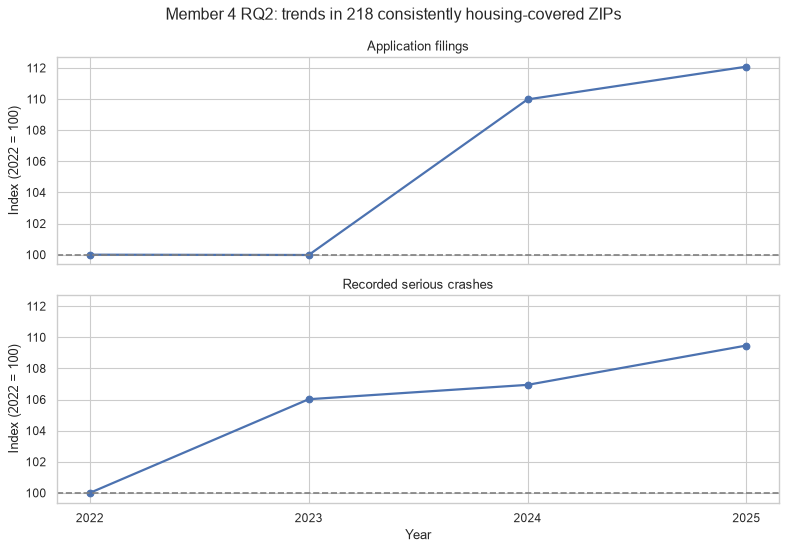

**Finding:** in the balanced panel, filings changed **+12.1%** and recorded serious crashes **+9.5%** between 2022 and 2025. Similar or different trends cannot by themselves identify a causal link.

,filing_count,crash_count
year,,
2022,141675.0,2492
2023,141648.0,2642
2024,155809.0,2665
2025,158792.0,2728


In [65]:
coverage = story.groupby("zip_code").agg(years=("year", "nunique"), housing_years=("has_housing_data", "sum"))
panel_zips = coverage.index[(coverage["years"] == 4) & (coverage["housing_years"] == 4)]
panel = story[story["zip_code"].isin(panel_zips)]
annual = panel.groupby("year")[["filing_count", "crash_count"]].sum(min_count=1)
assert (annual.loc[2022] > 0).all(), "A positive 2022 baseline is required."
indexed = annual.div(annual.loc[2022]) * 100
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, sharey=True)
for ax, metric, label in [(axes[0], "filing_count", "Application filings"), (axes[1], "crash_count", "Recorded serious crashes")]:
    ax.plot(indexed.index, indexed[metric], marker="o", linewidth=2)
    ax.axhline(100, color="gray", linestyle="--")
    ax.set(title=label, ylabel="Index (2022 = 100)")
axes[1].set(xlabel="Year", xticks=[2022, 2023, 2024, 2025])
fig.suptitle(f"Member 4 RQ2: trends in {len(panel_zips)} consistently housing-covered ZIPs")
plt.tight_layout()
plt.show()
filing_pct = indexed.loc[2025, "filing_count"] - 100
crash_pct = indexed.loc[2025, "crash_count"] - 100
display(Markdown(f"**Finding:** in the balanced panel, filings changed **{filing_pct:+.1f}%** "
                 f"and recorded serious crashes **{crash_pct:+.1f}%** between 2022 and 2025. "
                 "Similar or different trends cannot by themselves identify a causal link."))
display(annual)

## Key findings - calculated from this run
The summary below is also a draft handoff for Member 5's website. The two Member 4 charts above add a city-level geographic and temporal view to Member 3's ZIP-level comparisons.

In [66]:
display(Markdown(
    f"- The final table contains **{len(story):,} ZIP-years** across **{story['zip_code'].nunique()} ZIPs**.\n"
    f"- It retains **{story['filing_count'].sum():,.0f} filings** and **{story['crash_count'].sum():,.0f} recorded serious crashes**.\n"
    f"- **{story['approximate_zip_filings'].sum():,.0f} housing filings** use the approximate ZIP fallback; official postcode is preferred.\n"
    f"- Endpoint-change association across complete ZIPs: **r = {r:.3f}**.\n"
    f"- Lagged association: pooled **r = {r_b:.3f}**, within-ZIP **r = {r_w:.3f}**. "
    "Neither coefficient identifies a causal construction effect.\n"
    f"- **{story['jobs_with_known_units'].sum():,.0f} of {story['unique_job_count'].sum():,.0f} first-observed jobs** "
    "have complete reported unit pairs; unit totals do not represent completed homes."
))

- The final table contains **881 ZIP-years** across **222 ZIPs**.
- It retains **597,934 filings** and **10,531 recorded serious crashes**.
- **173 housing filings** use the approximate ZIP fallback; official postcode is preferred.
- Endpoint-change association across complete ZIPs: **r = -0.069**.
- Lagged association: pooled **r = 0.403**, within-ZIP **r = 0.056**. Neither coefficient identifies a causal construction effect.
- **298,176 of 346,294 first-observed jobs** have complete reported unit pairs; unit totals do not represent completed homes.

## Limitations and responsible interpretation
- **Correlation is not causation.** Population, traffic exposure, density, road design and land use are not controlled. No personal-risk or policy-effect estimate is possible.
- DOB filings include amendments and non-residential work. New-building labels are filing categories, not completion certificates. Job-cohort unit reports can be revised, are incomplete, and are attributed to first observation within this window.
- A conservative >10,000-unit screen quarantines suspicious values, rather than claiming to know their correct values. Partial unit totals cover reporting jobs only.
- The source APIs are mutable snapshots; crash severity can be revised. Cache metadata documents retrieval. Only full years 2022-2025 are compared.
- SIRTA covers serious/fatal crashes, not all collisions. Excluded/missing ZIPs and approximate recovery affect coverage. Zero recorded events is not proof that no real-world events occurred.
- Some official ZIPs have no source coordinates: retain them for counts/charts but omit them from maps with an explicit coverage notice. Never invent a map point.\n- ZIP aggregation hides street-level patterns. Official housing postcode is preferable to nearby-crash guesses; fallback remains flagged and can introduce boundary error/selection bias.
- Repeated ZIP-years and spatial dependence violate simple independent-observation assumptions. Endpoint-change p-values in Member 3 are exploratory and do not account for spatial dependence; no null result proves absence of an effect.
- The four-year window and assumed one-year lag are limited; filing dates do not say when construction occurred.

## NYC relevance and impact
Use the dashboard to identify places where application activity and serious crashes coincide and prioritize **further investigation**, not to blame construction or rank neighborhood safety. NYC planners and DOT could combine this screening with construction timelines, population, traffic counts and street-level evidence before interventions.

## Visualization review
All research charts identify their unit (ZIP-year, borough-year, job cohort or known-time crashes), label axes/color scales and avoid dual-axis causal storytelling. Undefined ratios remain missing. Each of Members 1-4 has two explicit research questions with corresponding charts and calculated interpretation.

## Contributions and AI transparency
Member 1: housing; Member 2 (Mariam): transportation; Member 3 (Aya Sweed): integration; Member 4: this consolidation, two additional charts and synthesis. Member 5's website/deployment is **not implemented in this revision**. Corrections/assembly were AI-assisted at the user's request; see `docs/prompts.md`. Team review is still required.

## Sources
- [DOB NOW Build Job Application Filings (H5)](https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd)
- [SIRTA (T4)](https://data.cityofnewyork.us/Transportation/Serious-Injury-Response-Tracking-Analysis-Program-/xeqp-qz8h)
- Data dictionaries in `docs/`; machine-readable column explanations in Member 3's export section.